# Практичне завдання 2. Логістична регресія та федеративне навчання

**Виконала:** Зімірська Юліана, група ФЕІ-42

**Датасет:** [Dry Bean Dataset (Kaggle)](https://www.kaggle.com/datasets/muratkokludataset/dry-bean-dataset) — файл `Dry_Bean_Dataset.xlsx` (або `.csv`) має лежати поруч із ноутбуком.

**Структура:**
1. Дослідження даних і попередня обробка
2. Багатокласова логістична регресія на numpy
3. Централізована базова модель
4. Розподіл даних між клієнтами та сервером
5. Симуляція федеративного навчання (FedAvg)
6. Дослідження ефектів FL (обов'язкові експерименти + зважування FedAvg)
7. Додаткові експерименти А (кількість клієнтів) і Б (персоналізація)
8. Відповіді на теоретичні питання та загальний висновок

Модель, функція втрат, градієнти, навчання та агрегація FedAvg реалізовані самостійно на numpy. `scikit-learn` використано лише для метрик, стратифікованого розбиття, аналізу ознак і (окремо позначено) для допоміжної перевірки коректності.

In [1]:
import warnings
warnings.filterwarnings('ignore')

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.feature_selection import f_classif, mutual_info_classif
from sklearn.metrics import (accuracy_score, f1_score, balanced_accuracy_score,
                             log_loss, confusion_matrix, ConfusionMatrixDisplay)

SEED = 42                      # фіксоване зерно для відтворюваності всіх експериментів
EPS = 1e-12

pd.set_option('display.float_format', '{:.4f}'.format)
pd.set_option('display.width', 160)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 100

---
## Етап 1. Дослідження даних та попередня обробка

### 1.1 Первинний аналіз даних

**Чому Dry Bean підходить для завдання та для FL:**
- багатокласова класифікація: 7 сортів квасолі (≥ 3 класів);
- ~13.6 тис. прикладів — достатньо, щоб розділити на тест, валідацію та 3–10 клієнтів, і в кожного клієнта лишилося сотні–тисячі прикладів;
- усі 16 ознак числові (геометрія зерна з комп'ютерного зору), тож лінійна модель на них працює добре, а результат легко інтерпретувати;
- класи незбалансовані (є рідкісний BOMBAY) — це робить розподіл Non-IID за Діріхле особливо показовим: окремі клієнти легко «втрачають» цілі класи;
- сценарій реалістичний для FL: різні ферми/лабораторії фотографують власні партії зерна, і кожна вирощує свій набір сортів.

In [2]:
# Файл з Kaggle: Dry_Bean_Dataset.xlsx (або .csv) — покласти поруч із ноутбуком
candidates = [Path('Dry_Bean_Dataset.xlsx'), Path('Dry_Bean_Dataset.csv'),
              Path('Dry_Bean_Dataset/Dry_Bean_Dataset.xlsx')]
DATA_PATH = next(p for p in candidates if p.exists())
df_raw = pd.read_excel(DATA_PATH) if DATA_PATH.suffix == '.xlsx' else pd.read_csv(DATA_PATH)

print('Розмір:', df_raw.shape)
df_raw.head()

Розмір: (13611, 17)


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.2910,208.1781,173.8887,1.1972,0.5498,28715,190.1411,0.7639,0.9889,0.9580,0.9134,0.0073,0.0031,0.8342,0.9987,SEKER
1,28734,638.0180,200.5248,182.7344,1.0974,0.4118,29172,191.2728,0.7840,0.9850,0.8870,0.9539,0.0070,0.0036,0.9099,0.9984,SEKER
2,29380,624.1100,212.8261,175.9311,1.2097,0.5627,29690,193.4109,0.7781,0.9896,0.9478,0.9088,0.0072,0.0030,0.8259,0.9991,SEKER
3,30008,645.8840,210.5580,182.5165,1.1536,0.4986,30724,195.4671,0.7827,0.9767,0.9039,0.9283,0.0070,0.0032,0.8618,0.9942,SEKER
4,30140,620.1340,201.8479,190.2793,1.0608,0.3337,30417,195.8965,0.7731,0.9909,0.9849,0.9705,0.0067,0.0037,0.9419,0.9992,SEKER


In [3]:
info = pd.DataFrame({'dtype': df_raw.dtypes.astype(str),
                     'пропуски': df_raw.isna().sum(),
                     'унікальних': df_raw.nunique()})
print('Дублікатів рядків:', df_raw.duplicated().sum())
info

Дублікатів рядків: 68


,dtype,пропуски,унікальних
Area,int64,0,12011
Perimeter,float64,0,13416
MajorAxisLength,float64,0,13543
MinorAxisLength,float64,0,13543
AspectRation,float64,0,13543
Eccentricity,float64,0,13543
ConvexArea,int64,0,12066
EquivDiameter,float64,0,12011
Extent,float64,0,13535
Solidity,float64,0,13526


**Висновок.** 16 числових ознак (`int64`/`float64`), ціль `Class` — рядок із 7 значеннями. Пропусків немає, тому імпутація не потрібна. Знайдено **68 повних дублікатів** — їх видаляємо *до* розбиття: інакше одна й та сама зернина могла б потрапити і в train, і в test, що завищило б оцінку якості (прихований витік). Видалення дублікатів нічого не «навчає» на даних, тому робити його до розбиття коректно.

Після видалення дублікатів: (13543, 17)


,кількість,%
Class,,
DERMASON,3546,26.1800
SIRA,2636,19.4600
SEKER,2027,14.9700
HOROZ,1860,13.7300
CALI,1630,12.0400
BARBUNYA,1322,9.7600
BOMBAY,522,3.8500


Дисбаланс (max/min): 6.79


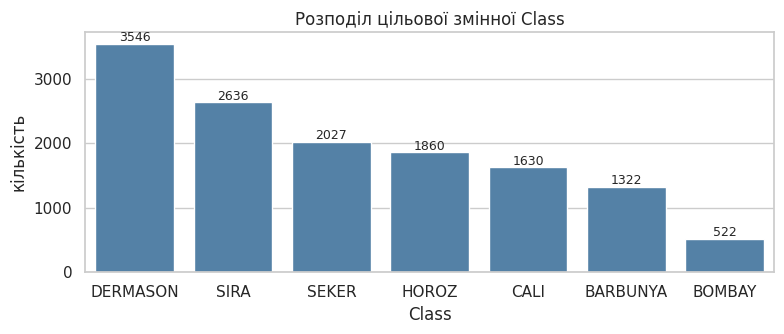

In [4]:
df = df_raw.drop_duplicates().reset_index(drop=True)
TARGET = 'Class'
FEATURES_ALL = [c for c in df.columns if c != TARGET]
print('Після видалення дублікатів:', df.shape)

counts = df[TARGET].value_counts()
share = (counts / counts.sum() * 100).round(2)
display(pd.DataFrame({'кількість': counts, '%': share}))
print(f'Дисбаланс (max/min): {counts.max() / counts.min():.2f}')

fig, ax = plt.subplots(figsize=(8, 3.5))
sns.barplot(x=counts.index, y=counts.values, ax=ax, color='steelblue')
for i, v in enumerate(counts.values):
    ax.text(i, v + 40, str(v), ha='center', fontsize=9)
ax.set_title('Розподіл цільової змінної Class'); ax.set_ylabel('кількість')
plt.tight_layout(); plt.show()

**Що показано:** розподіл сортів. **Закономірність:** найбільший клас DERMASON (26%), найменший BOMBAY (3.9%), співвідношення ≈ 6.8 : 1. **Чому важливо:** accuracy при дисбалансі може приховувати погану якість на рідкісних класах, тому, крім accuracy, дивимось на **macro-F1** і **balanced accuracy** (усереднення по класах з однаковою вагою). Усі розбиття робимо **стратифікованими**.

In [5]:
desc = df[FEATURES_ALL].describe().T
desc['skew'] = df[FEATURES_ALL].skew()
desc

,count,mean,std,min,25%,50%,75%,max,skew
Area,13543.0000,53048.4604,29392.4383,20420.0000,36282.5000,44580.0000,61382.0000,254616.0000,2.9471
Perimeter,13543.0000,854.9934,214.7227,524.7360,703.2300,793.8960,977.1465,1985.3700,1.6280
MajorAxisLength,13543.0000,319.8956,85.8093,183.6012,253.0868,296.4046,376.3125,738.8602,1.3658
MinorAxisLength,13543.0000,202.3653,45.0516,122.5127,175.8864,192.4911,217.2454,460.1985,2.2320
AspectRation,13543.0000,1.5811,0.2452,1.0249,1.4307,1.5499,1.7039,2.4303,0.5890
Eccentricity,13543.0000,0.7503,0.0919,0.2190,0.7151,0.7640,0.8097,0.9114,-1.0649
ConvexArea,13543.0000,53767.9867,29844.2485,20684.0000,36673.0000,45122.0000,62360.0000,263261.0000,2.9361
EquivDiameter,13543.0000,253.0341,59.3077,161.2438,214.9333,238.2457,279.5604,569.3744,1.9473
Extent,13543.0000,0.7498,0.0489,0.5553,0.7187,0.7599,0.7868,0.8662,-0.8957
Solidity,13543.0000,0.9872,0.0047,0.9192,0.9857,0.9883,0.9900,0.9947,-2.5469


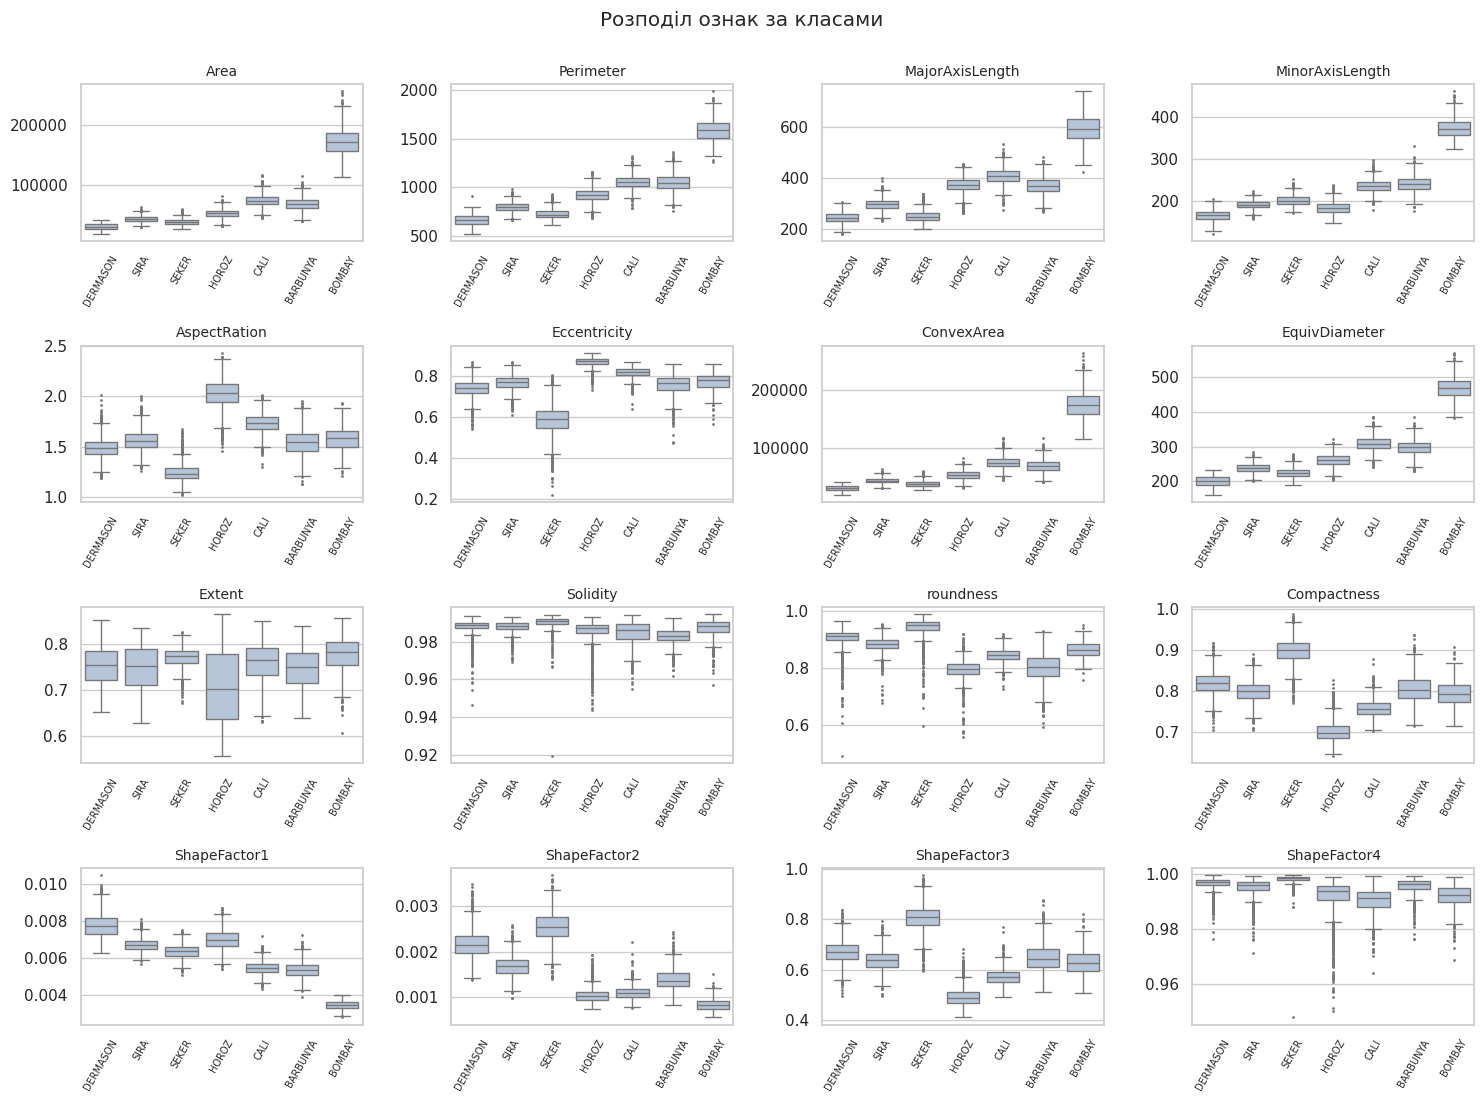

In [6]:
fig, axes = plt.subplots(4, 4, figsize=(15, 11))
order = counts.index.tolist()
for ax, col in zip(axes.ravel(), FEATURES_ALL):
    sns.boxplot(data=df, x=TARGET, y=col, order=order, ax=ax, fliersize=1, color='lightsteelblue')
    ax.set_title(col, fontsize=10); ax.set_xlabel(''); ax.set_ylabel('')
    ax.tick_params(axis='x', rotation=60, labelsize=7)
plt.suptitle('Розподіл ознак за класами', y=1.0)
plt.tight_layout(); plt.show()

**Що показано:** описові статистики та розподіл кожної ознаки в розрізі класів.

**Закономірності:**
- Ознаки мають дуже різні масштаби: `Area` ~ $10^4$–$10^5$, а `ShapeFactor2` ~ $10^{-3}$. Без масштабування градієнтний спуск по `W` буде дуже «витягнутим» і повільним → стандартизація обов'язкова.
- Розмірні ознаки (`Area`, `ConvexArea`, `MinorAxisLength`) сильно скошені праворуч (skew 2–3), `Solidity`, `ShapeFactor4` — ліворуч (−2.5…−2.8). Хвости дає переважно BOMBAY — найбільші зерна.
- BOMBAY відокремлюється майже будь-якою розмірною ознакою; SEKER — за формою (`roundness`, `Compactness`); найбільше перекриваються DERMASON і SIRA — очікуємо, що саме між ними модель плутатиметься найчастіше.

Сильні кореляції між ознаками та їх зв'язок із ціллю аналізуємо в п. 1.3 — вже *на FL Train Pool*, щоб рішення про відбір ознак не бачили тест.

### 1.2 Розбиття вибірки

Розбиття виконуємо **одразу після мінімальної очистки**, до відбору ознак, масштабування та кодування, щоб жоден крок, який щось «навчає» з даних, не бачив валідацію чи тест.

| Множина | Частка | Призначення |
|---|---|---|
| Global Test | 15% | лише фінальна оцінка; зберігається на сервері |
| Global Validation | 15% | підбір гіперпараметрів, моніторинг раундів FL; на сервері, клієнтам не передається |
| FL Train Pool | 70% | розподіляється між клієнтами; для централізованої моделі — весь train |

**Питання: чому розбиття — до масштабування/кодування? Що таке Data Leakage?**

**Data Leakage (витік даних)** — ситуація, коли при навчанні моделі (або при виборі її налаштувань) використовується інформація, недоступна в момент реального застосування, найчастіше — інформація з тестової/валідаційної вибірки. Наслідок — завищена, нечесна оцінка якості.

Масштабування, target encoding, відбір ознак тощо — це *теж навчання*: вони оцінюють параметри (середні, дисперсії, середні цілі по категорії, список корисних ознак) з даних. Якщо зробити їх до розбиття, у ці параметри потрапить тест, і модель опосередковано «побачить» дані, на яких її потім оцінюють. Тому: спочатку розбиття → потім усі перетворення навчаються лише на train → застосовуються до val/test як є.

In [7]:
TEST_SIZE, VAL_SIZE = 0.15, 0.15   # частки від усього датасету

# 1) відокремлюємо Global Test
df_rest, df_test = train_test_split(df, test_size=TEST_SIZE, stratify=df[TARGET], random_state=SEED)
# 2) з решти відокремлюємо Global Validation (0.15 від усього => 0.15/0.85 від залишку)
df_pool, df_val = train_test_split(df_rest, test_size=VAL_SIZE / (1 - TEST_SIZE),
                                   stratify=df_rest[TARGET], random_state=SEED)

split_info = pd.DataFrame({
    'Множина': ['FL Train Pool', 'Global Validation', 'Global Test'],
    'Хто має доступ': ['розподіляється між клієнтами', 'лише сервер', 'лише сервер (фінальна оцінка)'],
    'Кількість': [len(df_pool), len(df_val), len(df_test)],
})
split_info['%'] = (split_info['Кількість'] / len(df) * 100).round(1)
display(split_info)

# перевірка стратифікації: частки класів у кожній множині
strat = pd.DataFrame({name: d[TARGET].value_counts(normalize=True) * 100
                      for name, d in [('весь датасет', df), ('FL Train Pool', df_pool),
                                      ('Validation', df_val), ('Test', df_test)]}).round(2)
strat

,Множина,Хто має доступ,Кількість,%
0,FL Train Pool,розподіляється між клієнтами,9479,70.0000
1,Global Validation,лише сервер,2032,15.0000
2,Global Test,лише сервер (фінальна оцінка),2032,15.0000


,весь датасет,FL Train Pool,Validation,Test
Class,,,,
DERMASON,26.1800,26.1800,26.1800,26.1800
SIRA,19.4600,19.4500,19.4900,19.4900
SEKER,14.9700,14.9700,14.9600,14.9600
HOROZ,13.7300,13.7400,13.7300,13.7300
CALI,12.0400,12.0300,12.0600,12.0600
BARBUNYA,9.7600,9.7700,9.7400,9.7400
BOMBAY,3.8500,3.8600,3.8400,3.8400


**Висновок.** Отримали 9479 / 2032 / 2032 прикладів (70/15/15%). Частки класів у всіх трьох множинах збігаються з точністю до сотих відсотка — стратифікація спрацювала, тож і валідація, і тест репрезентують усі 7 класів, включно з рідкісним BOMBAY.

### 1.3 Відбір ознак (лише FL Train Pool)

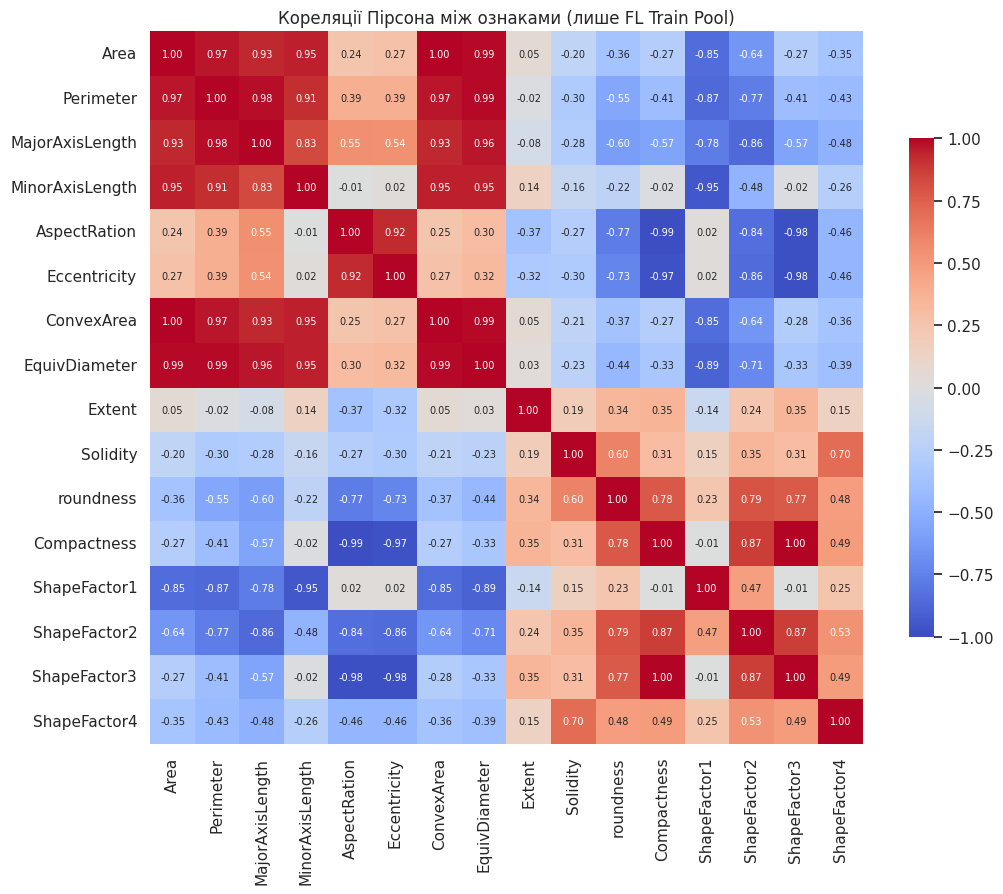

Пари з |r| > 0.95:


,ознака 1,ознака 2,r
6,Area,ConvexArea,0.9999
190,Compactness,ShapeFactor3,0.9987
23,Perimeter,EquivDiameter,0.9917
75,AspectRation,Compactness,-0.9876
103,ConvexArea,EquivDiameter,0.9853
7,Area,EquivDiameter,0.9850
94,Eccentricity,ShapeFactor3,-0.9811
78,AspectRation,ShapeFactor3,-0.9785
18,Perimeter,MajorAxisLength,0.9779
91,Eccentricity,Compactness,-0.9704


In [8]:
Xp = df_pool[FEATURES_ALL]
corr = Xp.corr()

plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1,
            annot_kws={'size': 7}, square=True, cbar_kws={'shrink': .7})
plt.title('Кореляції Пірсона між ознаками (лише FL Train Pool)')
plt.tight_layout(); plt.show()

pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
         .rename('r').reset_index().rename(columns={'level_0': 'ознака 1', 'level_1': 'ознака 2'}))
pairs = pairs[pairs['r'].abs() > 0.95].sort_values('r', key=np.abs, ascending=False)
print('Пари з |r| > 0.95:')
pairs

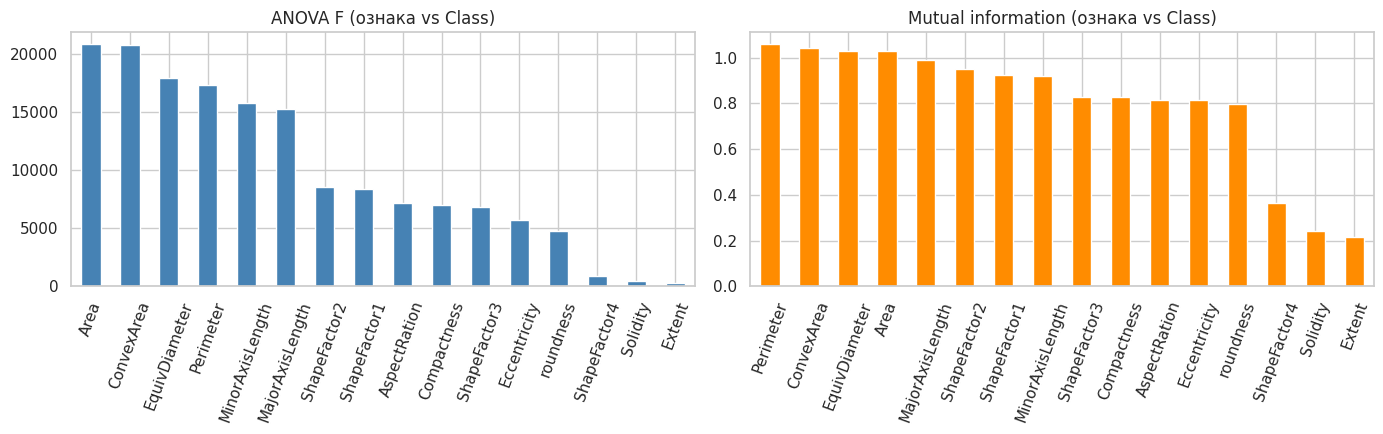

,F_stat,mutual_info
Area,20803.0650,1.0296
ConvexArea,20792.5532,1.0402
EquivDiameter,17921.9319,1.0297
Perimeter,17270.9258,1.0580
MinorAxisLength,15742.4675,0.9199
MajorAxisLength,15210.1515,0.9905
ShapeFactor2,8578.7942,0.9509
ShapeFactor1,8393.8490,0.9262
AspectRation,7157.8693,0.8138
Compactness,7018.1983,0.8297


In [9]:
# Зв'язок ознак із цільовою змінною (категоріальною): ANOVA F-статистика та взаємна інформація
F, _ = f_classif(Xp, df_pool[TARGET])
MI = mutual_info_classif(Xp, df_pool[TARGET], random_state=SEED)
relevance = pd.DataFrame({'F_stat': F, 'mutual_info': MI}, index=FEATURES_ALL).sort_values('F_stat', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
relevance['F_stat'].plot.bar(ax=axes[0], color='steelblue', title='ANOVA F (ознака vs Class)')
relevance['mutual_info'].sort_values(ascending=False).plot.bar(ax=axes[1], color='darkorange',
                                                              title='Mutual information (ознака vs Class)')
for ax in axes: ax.tick_params(axis='x', rotation=70)
plt.tight_layout(); plt.show()
relevance

In [10]:
# Жадібний відбір: йдемо від найінформативнішої ознаки (за F) і відкидаємо ті,
# що майже дублюють уже відібрані (|r| > CORR_THR)
CORR_THR = 0.95
selected, dropped = [], {}
for f in relevance.index:
    dup = [s for s in selected if abs(corr.loc[f, s]) > CORR_THR]
    if dup:
        dropped[f] = f'{dup[0]} (r={corr.loc[f, dup[0]]:.3f})'
    else:
        selected.append(f)

FEATURES = selected
print(f'Відібрано {len(FEATURES)} з {len(FEATURES_ALL)} ознак:')
print(FEATURES)
print('\nВідкинуто (дублює):')
for k, v in dropped.items():
    print(f'  {k:16s} -> {v}')

Відібрано 10 з 16 ознак:
['Area', 'MajorAxisLength', 'ShapeFactor2', 'ShapeFactor1', 'AspectRation', 'Eccentricity', 'roundness', 'ShapeFactor4', 'Solidity', 'Extent']

Відкинуто (дублює):
  ConvexArea       -> Area (r=1.000)
  EquivDiameter    -> Area (r=0.985)
  Perimeter        -> Area (r=0.967)
  MinorAxisLength  -> Area (r=0.952)
  Compactness      -> AspectRation (r=-0.988)
  ShapeFactor3     -> AspectRation (r=-0.978)


**Що показано:** теплова карта кореляцій, пари з $|r|>0.95$, а також сила зв'язку кожної ознаки з класом (ANOVA F і mutual information; кореляцію Пірсона з ціллю напряму рахувати некоректно, бо ціль — номінальна).

**Закономірності та пояснення:**
- **Сильна мультиколінеарність** — очікувана, бо ознаки є функціями одна одної: `ConvexArea` ≈ `Area` ($r=0.9999$), `EquivDiameter` $=\sqrt{4\cdot Area/\pi}$, `ShapeFactor3` $=$ `Compactness`$^2$ ($r=0.999$), `Compactness` і `AspectRation` обидві описують видовженість ($r=-0.988$).
- За релевантністю лідирують розмірні ознаки (`Area`, `Perimeter`, `ConvexArea`), найслабші — `Extent`, `Solidity`, `ShapeFactor4`, але і в них F-статистика значуща, тому їх не відкидаємо.

**Рішення.** Жадібний відбір: беремо ознаки за спаданням F і відкидаємо ті, що корелюють з уже відібраними сильніше ніж на 0.95. Залишилось **10 ознак з 16**. Для логістичної регресії з L2 мультиколінеарність не ламає навчання, але робить ваги нестабільними й неінтерпретованими (вага «розмазується» між майже однаковими ознаками), а для FL — зайві параметри, які треба передавати. Чи не втратили ми якість, перевіряємо на валідації в Етапі 3.

### 1.4 Кодування

Категоріальних **ознак** у Dry Bean немає — усі 16 числові, тому One-Hot / Ordinal / Target Encoding для ознак не потрібні. Для довідки: для номінальних ознак без порядку обирали б One-Hot (не вносить хибного порядку), для ознак з природним порядком — Ordinal, для категорій з великою кількістю значень — Target Encoding (обов'язково з навчанням лише на train, бо він напряму використовує ціль і найбільш схильний до витоку).

Кодуємо лише **цільову змінну**: сорт → індекс 0…6 (алфавітний порядок фіксований), а для навчання — one-hot матриця $Y\in\{0,1\}^{m\times C}$.

In [11]:
CLASSES = sorted(df[TARGET].unique())
C = len(CLASSES)
cls2id = {c: i for i, c in enumerate(CLASSES)}

def one_hot(y, n_classes):
    """y: (m,) цілі мітки -> Y: (m, C) one-hot"""
    Y = np.zeros((len(y), n_classes))
    Y[np.arange(len(y)), y] = 1.0
    return Y

y_pool = df_pool[TARGET].map(cls2id).to_numpy()
y_val  = df_val[TARGET].map(cls2id).to_numpy()
y_test = df_test[TARGET].map(cls2id).to_numpy()
print(dict(enumerate(CLASSES)))

{0: 'BARBUNYA', 1: 'BOMBAY', 2: 'CALI', 3: 'DERMASON', 4: 'HOROZ', 5: 'SEKER', 6: 'SIRA'}


### 1.5 Масштабування

Використовуємо **стандартизацію** $x' = (x-\mu)/\sigma$: логістичній регресії з градієнтним спуском важливо, щоб ознаки мали порівнянний масштаб, а скошені ознаки з викидами (BOMBAY) гірше переносять min-max нормалізацію (викид стискає решту значень у вузький діапазон).

Реалізовано **підхід (б) — федеративний**: кожен клієнт надсилає лише $n_k$, локальні середні $\mu_k$ та дисперсії $\sigma_k^2$, сервер об'єднує їх зважено:

$$\mu = \sum_k \frac{n_k}{n}\mu_k,\qquad \sigma^2 = \sum_k \frac{n_k}{n}\left(\sigma_k^2 + (\mu_k-\mu)^2\right)$$

(друга формула — розклад загальної дисперсії на внутрішньогрупову та міжгрупову). Ці статистики потім застосовуються до всіх клієнтів, валідації та тесту. Global Validation і Global Test у обчисленні статистик участі не беруть.

In [12]:
def client_stats(X):
    """Те, що клієнт надсилає серверу: лише агреговані статистики, не сирі дані."""
    return len(X), X.mean(axis=0), X.var(axis=0)

def aggregate_stats(stats):
    """Сервер: зважене за n_k об'єднання середніх і дисперсій (формула для об'єднаної дисперсії)."""
    n = np.array([s[0] for s in stats], dtype=float)
    means = np.stack([s[1] for s in stats]); vars_ = np.stack([s[2] for s in stats])
    w = (n / n.sum())[:, None]
    mean = (w * means).sum(axis=0)
    var = (w * (vars_ + (means - mean) ** 2)).sum(axis=0)   # внутрішньогрупова + міжгрупова
    return mean, np.sqrt(var)

class Standardizer:
    def __init__(self, mean, std):
        self.mean, self.std = mean, np.where(std < EPS, 1.0, std)
    def transform(self, X):
        return (X - self.mean) / self.std

def prepare(frame, features):
    return frame[features].to_numpy(dtype=float)

Xpool_raw = prepare(df_pool, FEATURES_ALL)

# Демонстрація підходу (б): 5 клієнтів рахують локальні статистики, сервер агрегує
demo_parts = np.array_split(np.random.default_rng(SEED).permutation(len(Xpool_raw)), 5)
fed_mean, fed_std = aggregate_stats([client_stats(Xpool_raw[p]) for p in demo_parts])
print('Федеративні статистики == статистики всього FL Train Pool:',
      np.allclose(fed_mean, Xpool_raw.mean(0)), np.allclose(fed_std, Xpool_raw.std(0)))

Федеративні статистики == статистики всього FL Train Pool: True True


In [13]:
def make_matrices(features):
    Xp, Xv, Xt = prepare(df_pool, features), prepare(df_val, features), prepare(df_test, features)
    parts = np.array_split(np.random.default_rng(SEED).permutation(len(Xp)), 5)
    scaler = Standardizer(*aggregate_stats([client_stats(Xp[p]) for p in parts]))   # тільки train pool!
    return scaler.transform(Xp), scaler.transform(Xv), scaler.transform(Xt)

X_pool, X_val, X_test = make_matrices(FEATURES)
Xall_pool, Xall_val, Xall_test = make_matrices(FEATURES_ALL)   # для перевірки відбору ознак

print('X_pool', X_pool.shape, '| X_val', X_val.shape, '| X_test', X_test.shape)
print('mean(pool) ≈ 0:', np.abs(X_pool.mean(0)).max().round(6), '| std(pool) ≈ 1:', X_pool.std(0).round(3).min())
print('mean(test) (не рівно 0 — це нормально):', X_test.mean(0).round(3)[:5])

X_pool (9479, 10) | X_val (2032, 10) | X_test (2032, 10)
mean(pool) ≈ 0: 0.0 | std(pool) ≈ 1: 1.0
mean(test) (не рівно 0 — це нормально): [ 0.004  0.009 -0.013 -0.013  0.007]


**Висновок.** Федеративно агреговані статистики **точно** (до похибки float) збігаються зі статистиками всього FL Train Pool. Це не випадковість: формула об'єднаної дисперсії точна для *будь-якого* розбиття пулу на клієнтів. Тому один і той самий скейлер коректний для всіх сценаріїв розподілу (IID, будь-яке α, будь-яке K), і підходи (а) та (б) дають однаковий результат — але в (б) сервер ніколи не бачить сирих даних.

На train середнє = 0 і std = 1, на тесті середні трохи відрізняються від 0 — так і має бути, адже параметри скейлера тесту «не знають».

---
## Етап 2. Багатокласова логістична регресія на numpy

Позначення: $X\in\mathbb R^{m\times d}$, $Y\in\{0,1\}^{m\times C}$, $W\in\mathbb R^{d\times C}$, $b\in\mathbb R^{1\times C}$.

- Лінійна частина: $Z = XW + b$
- Softmax (по рядках): $P_{ic} = \dfrac{e^{Z_{ic}}}{\sum_j e^{Z_{ij}}}$. Для стабільності від кожного рядка віднімаємо його максимум: $\text{softmax}(z)=\text{softmax}(z-\max z)$, бо множник $e^{-\max z}$ скорочується; тоді найбільший показник експоненти $=0$ і переповнення неможливе.
- Втрати з Ridge: $J = -\dfrac1m\sum_i\sum_c Y_{ic}\log P_{ic} + \dfrac\lambda2\|W\|_F^2$. Для обчислення $\log P$ використано `log_softmax` ($Z - \log\sum e^{Z}$) — стабільніше, ніж $\log$ від уже обчисленої ймовірності, яка може бути 0.
- Градієнти: $\dfrac{\partial J}{\partial W} = \dfrac1m X^\top(P-Y) + \lambda W$, $\dfrac{\partial J}{\partial b} = \dfrac1m \mathbf 1_m^\top (P-Y)$; $b$ не регуляризується.

Усі обчислення по прикладах — векторизовані; цикли лише по епохах і батчах. Методи `get_params` / `set_params` потрібні для передачі моделі між сервером і клієнтами у FedAvg.

In [14]:
def softmax(Z):
    """Чисельно стабільний softmax по рядках: віднімаємо максимум рядка."""
    Z = Z - Z.max(axis=1, keepdims=True)
    E = np.exp(Z)
    return E / E.sum(axis=1, keepdims=True)

def log_softmax(Z):
    Z = Z - Z.max(axis=1, keepdims=True)
    return Z - np.log(np.exp(Z).sum(axis=1, keepdims=True))


class SoftmaxRegression:
    """Багатокласова логістична регресія (softmax) з Ridge (L2) регуляризацією, лише numpy."""

    def __init__(self, n_features, n_classes, lam=0.0, seed=SEED, init_std=0.01):
        rng = np.random.default_rng(seed)
        self.W = rng.normal(0.0, init_std, size=(n_features, n_classes))   # (d, C)
        self.b = np.zeros((1, n_classes))                                   # (1, C)
        self.lam = lam

    # --- параметри (потрібні для FedAvg) ---
    def get_params(self):
        return {'W': self.W.copy(), 'b': self.b.copy()}

    def set_params(self, params):
        self.W, self.b = params['W'].copy(), params['b'].copy()

    # --- пряме поширення ---
    def logits(self, X):
        return X @ self.W + self.b                        # Z = XW + b

    def predict_proba(self, X):
        return softmax(self.logits(X))

    def predict(self, X):
        return self.predict_proba(X).argmax(axis=1)

    # --- функція втрат ---
    def loss(self, X, Y):
        m = X.shape[0]
        ce = -np.sum(Y * log_softmax(self.logits(X))) / m      # крос-ентропія без циклів
        return ce + 0.5 * self.lam * np.sum(self.W ** 2)       # + λ/2 ||W||_F^2 (b не регуляризуємо)

    # --- градієнти ---
    def gradients(self, X, Y):
        m = X.shape[0]
        G = self.predict_proba(X) - Y                           # P - Y, (m, C)
        dW = X.T @ G / m + self.lam * self.W                    # (d, C)
        db = G.sum(axis=0, keepdims=True) / m                   # 1ᵀ(P - Y) / m, (1, C)
        return dW, db

    # --- оновлення ---
    def update(self, dW, db, lr):
        self.W -= lr * dW
        self.b -= lr * db

    # --- міні-батчевий градієнтний спуск ---
    def fit(self, X, Y, epochs=50, lr=0.1, batch_size=64, X_val=None, Y_val=None, seed=SEED):
        rng = np.random.default_rng(seed)
        m = X.shape[0]
        hist = {'train_loss': [], 'val_loss': []}
        for _ in range(epochs):                                  # цикл по епохах — дозволено
            idx = rng.permutation(m)
            for start in range(0, m, batch_size):                # цикл по батчах — дозволено
                bi = idx[start:start + batch_size]
                dW, db = self.gradients(X[bi], Y[bi])
                self.update(dW, db, lr)
            hist['train_loss'].append(self.loss(X, Y))
            if X_val is not None:
                hist['val_loss'].append(self.loss(X_val, Y_val))
        return hist


def evaluate(model, X, y):
    P = model.predict_proba(X)
    pred = P.argmax(axis=1)
    return {'accuracy': accuracy_score(y, pred),
            'macro_f1': f1_score(y, pred, average='macro'),
            'balanced_acc': balanced_accuracy_score(y, pred),
            'log_loss': log_loss(y, np.clip(P, EPS, 1), labels=np.arange(P.shape[1]))}

Y_pool, Y_val = one_hot(y_pool, C), one_hot(y_val, C)

**Перевірка градієнтів.** Порівнюємо аналітичні градієнти з чисельними (центральна різниця $\frac{J(\theta+h)-J(\theta-h)}{2h}$) на 200 випадкових прикладах, з $\lambda=0.1$ і «великими» випадковими вагами, щоб перевірка була нетривіальною.

In [15]:
def numerical_grad(model, X, Y, h=1e-5):
    gW = np.zeros_like(model.W); gb = np.zeros_like(model.b)
    for P_, G_ in [(model.W, gW), (model.b, gb)]:
        it = np.nditer(P_, flags=['multi_index'])
        for _ in it:
            i = it.multi_index; old = P_[i]
            P_[i] = old + h; lp = model.loss(X, Y)
            P_[i] = old - h; lm = model.loss(X, Y)
            P_[i] = old; G_[i] = (lp - lm) / (2 * h)
    return gW, gb

rng = np.random.default_rng(0)
gc_model = SoftmaxRegression(X_pool.shape[1], C, lam=0.1, init_std=0.5)
sub = rng.choice(len(X_pool), 200, replace=False)
aW, ab = gc_model.gradients(X_pool[sub], Y_pool[sub])
nW, nb = numerical_grad(gc_model, X_pool[sub], Y_pool[sub])
rel = lambda a, n: np.linalg.norm(a - n) / (np.linalg.norm(a) + np.linalg.norm(n))
print(f'Відносна похибка dW: {rel(aW, nW):.2e}   db: {rel(ab, nb):.2e}')

# стабільність softmax на величезних логітах
print('softmax([1000, 1001, 1002]) =', softmax(np.array([[1000., 1001., 1002.]])).round(4))

Відносна похибка dW: 6.17e-11   db: 1.34e-10
softmax([1000, 1001, 1002]) = [[0.09   0.2447 0.6652]]


**Висновок.** Відносна похибка ~$10^{-10}$ (норма — $<10^{-7}$), тобто формули градієнтів, включно з L2-доданком, реалізовані правильно. Softmax на логітах порядку 1000 повертає коректні ймовірності без `overflow`/`nan` — віднімання максимуму працює.

---
## Етап 3. Централізована базова модель

Навчаємо на всьому FL Train Pool, гіперпараметри обираємо **лише за Global Validation** (критерій — val log-loss: він чутливий і до правильності класу, і до калібрування ймовірностей, і менш «східчастий», ніж accuracy). Кількість епох фіксована — 60.

**Крок 1.** Сітка: $lr\in\{0.01, 0.05, 0.1, 0.5\}$ × batch $\in\{32, 128, 512\}$ при $\lambda=0$.

In [16]:
EPOCHS = 60
d = X_pool.shape[1]

def train_eval(lr, bs, lam, X=X_pool, Y=Y_pool, Xv=X_val, Yv=Y_val, yv=y_val, epochs=EPOCHS):
    m = SoftmaxRegression(X.shape[1], C, lam=lam)
    h = m.fit(X, Y, epochs=epochs, lr=lr, batch_size=bs, X_val=Xv, Y_val=Yv)
    return m, h, evaluate(m, Xv, yv)

# Крок 1: швидкість навчання × розмір батчу (λ = 0)
grid_rows, curves = [], {}
for lr in [0.01, 0.05, 0.1, 0.5]:
    for bs in [32, 128, 512]:
        _, h, met = train_eval(lr, bs, 0.0)
        curves[(lr, bs)] = h
        grid_rows.append({'lr': lr, 'batch': bs, **met, 'final_train_loss': h['train_loss'][-1]})
grid = pd.DataFrame(grid_rows).sort_values('log_loss')
grid

,lr,batch,accuracy,macro_f1,balanced_acc,log_loss,final_train_loss
9,0.5000,32,0.9218,0.9307,0.9300,0.2305,0.2041
10,0.5000,128,0.9227,0.9310,0.9312,0.2350,0.2058
6,0.1000,32,0.9227,0.9308,0.9310,0.2363,0.2066
3,0.0500,32,0.9218,0.9295,0.9302,0.2431,0.2112
11,0.5000,512,0.9203,0.9281,0.9290,0.2498,0.2169
7,0.1000,128,0.9208,0.9286,0.9295,0.2549,0.2212
4,0.0500,128,0.9218,0.9297,0.9307,0.2752,0.2407
0,0.0100,32,0.9198,0.9273,0.9275,0.2848,0.2504
8,0.1000,512,0.9158,0.9234,0.9235,0.3086,0.2748
5,0.0500,512,0.9099,0.9176,0.9176,0.3645,0.3337


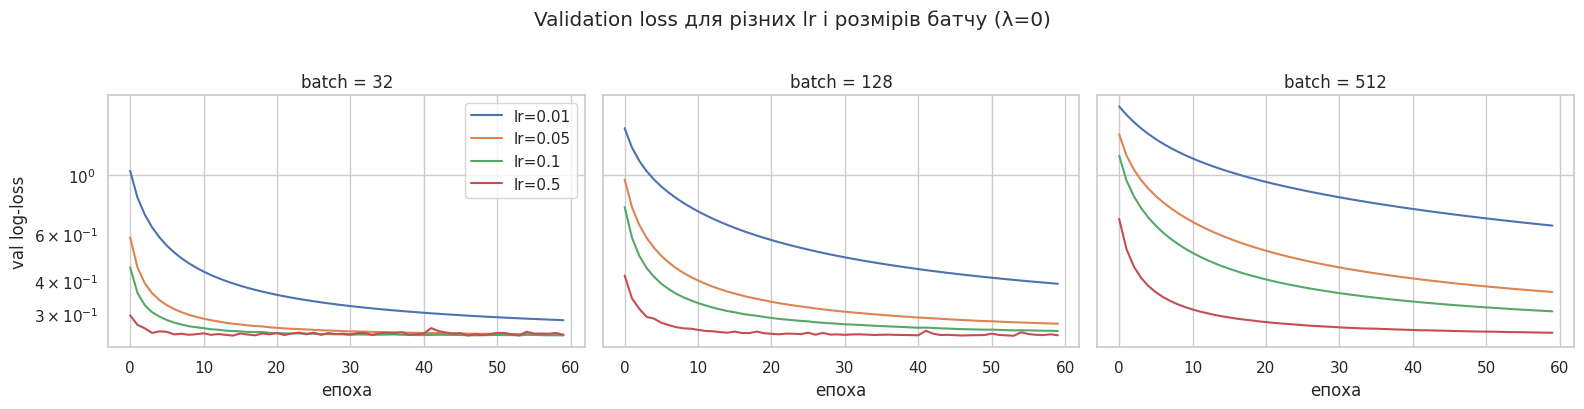

Обрано: lr=0.5, batch=32


In [17]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, bs in zip(axes, [32, 128, 512]):
    for lr in [0.01, 0.05, 0.1, 0.5]:
        ax.plot(curves[(lr, bs)]['val_loss'], label=f'lr={lr}')
    ax.set_title(f'batch = {bs}'); ax.set_xlabel('епоха'); ax.set_yscale('log')
axes[0].set_ylabel('val log-loss'); axes[0].legend()
plt.suptitle('Validation loss для різних lr і розмірів батчу (λ=0)', y=1.02)
plt.tight_layout(); plt.show()

best = grid.iloc[0]
LR, BS = float(best['lr']), int(best['batch'])
print(f'Обрано: lr={LR}, batch={BS}')

**Що показано:** криві val log-loss для 12 комбінацій та підсумкова таблиця.

**Закономірність:** чим менший $lr$ і більший батч, тим повільніше збігається модель: при `lr=0.01, batch=512` за 60 епох loss лише 0.65 (модель недонавчена), при `lr=0.5, batch=32` — 0.23. Розходження (зростання loss) немає навіть при $lr=0.5$.

**Чому:** за одну епоху робиться $m/\text{batch}$ кроків, тож малий батч = більше оновлень; великий $lr$ = довші кроки. Після стандартизації задача добре обумовлена й опукла, тому навіть $lr=0.5$ стабільний. Ціною малого батча є шумніші кроки, але при $m\approx9.5$ тис. і 60 епохах шум не заважає.

**Вибір:** `lr = 0.5`, `batch = 32` (мінімальний val log-loss 0.2305). Кілька верхніх конфігурацій різняться за accuracy в межах 0.1–0.3 п.п., тобто модель досягла «стелі» лінійного класифікатора.

,lambda,accuracy,macro_f1,balanced_acc,log_loss,||W||_F,train_loss(CE)
0,0.0000,0.9218,0.9307,0.9300,0.2305,17.5726,0.2041
1,0.0001,0.9227,0.9316,0.9312,0.2338,15.1154,0.2063
2,0.0010,0.9222,0.9307,0.9308,0.2598,10.2813,0.2292
3,0.0100,0.9090,0.9176,0.9141,0.3836,5.5297,0.3566
4,0.0300,0.8858,0.8964,0.8892,0.5287,3.7525,0.5068
5,0.1000,0.7510,0.7602,0.7504,0.7907,2.3219,0.7728


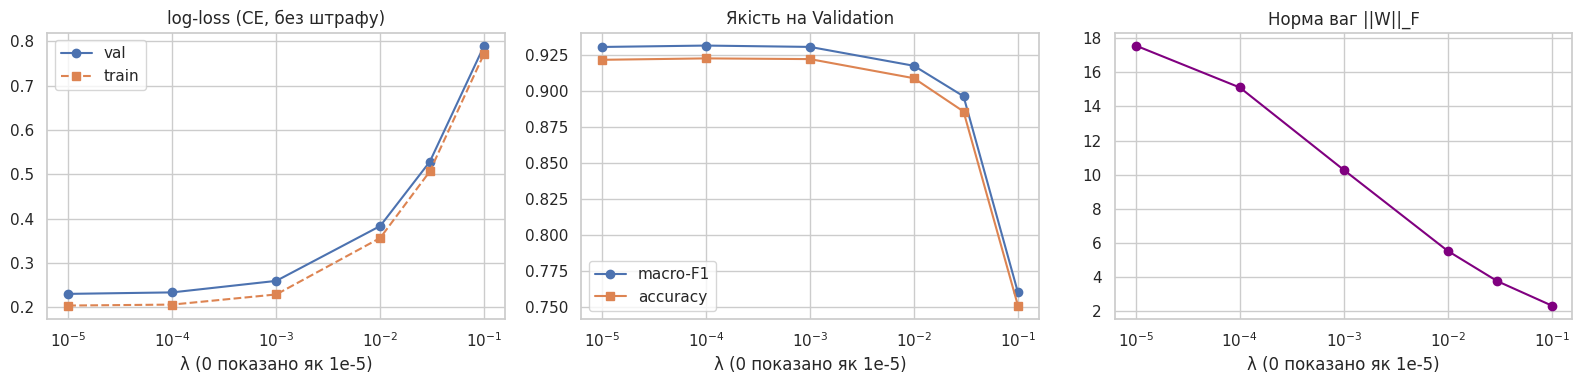

Обрано λ = 0.0


In [18]:
# Крок 2: вплив Ridge-регуляризації
lam_rows, lam_models = [], {}
for lam in [0.0, 1e-4, 1e-3, 1e-2, 3e-2, 1e-1]:
    m, h, met = train_eval(LR, BS, lam)
    lam_models[lam] = m
    lam_rows.append({'lambda': lam, **met, '||W||_F': np.linalg.norm(m.W),
                     'train_loss(CE)': evaluate(m, X_pool, y_pool)['log_loss']})
lam_df = pd.DataFrame(lam_rows)
display(lam_df)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
x = lam_df['lambda'].replace(0, 1e-5)
axes[0].semilogx(x, lam_df['log_loss'], 'o-', label='val'); axes[0].semilogx(x, lam_df['train_loss(CE)'], 's--', label='train')
axes[0].set_title('log-loss (CE, без штрафу)'); axes[0].legend()
axes[1].semilogx(x, lam_df['macro_f1'], 'o-', label='macro-F1'); axes[1].semilogx(x, lam_df['accuracy'], 's-', label='accuracy')
axes[1].set_title('Якість на Validation'); axes[1].legend()
axes[2].semilogx(x, lam_df['||W||_F'], 'o-', color='purple'); axes[2].set_title('Норма ваг ||W||_F')
for ax in axes: ax.set_xlabel('λ (0 показано як 1e-5)')
plt.tight_layout(); plt.show()

LAM = float(lam_df.sort_values('log_loss').iloc[0]['lambda'])
print('Обрано λ =', LAM)

**Що показано:** вплив $\lambda$ на якість (val), train-loss і норму ваг.

**Закономірність:** зі зростанням $\lambda$ норма $\|W\|_F$ монотонно падає (17.6 → 2.3), а якість при $\lambda\le10^{-3}$ практично не змінюється і далі різко падає (при $\lambda=0.1$ accuracy 0.75). Train і val loss весь час йдуть поруч.

**Чому:** у нас лише 10 ознак і ~9.5 тис. прикладів — лінійна модель має мало параметрів відносно даних і **не перенавчається** (train ≈ val). L2 тут не має чого «лікувати», а великий штраф викликає недонавчання: стискає ваги настільки, що модель не може розділити схожі класи. Крихітне $\lambda=10^{-4}$ дає +0.1 п.п. accuracy, але гірший log-loss — різниця в межах шуму.

**Вибір:** $\lambda = 0$ (найкращий val log-loss). Висновок: для цього датасету Ridge-регуляризація не потрібна; вона стала б корисною при великій кількості ознак, малій вибірці або сильній мультиколінеарності без відбору ознак.

In [19]:
# Перевірка відбору ознак на Validation (тест не використовується)
_, _, met_sel = train_eval(LR, BS, LAM)
_, _, met_all = train_eval(LR, BS, LAM, X=Xall_pool, Xv=Xall_val)
pd.DataFrame({f'відібрані ({len(FEATURES)})': met_sel, f'усі ({len(FEATURES_ALL)})': met_all}).T

,accuracy,macro_f1,balanced_acc,log_loss
відібрані (10),0.9218,0.9307,0.9300,0.2305
усі (16),0.9232,0.9318,0.9312,0.2309


**Перевірка відбору ознак.** 10 відібраних ознак проти всіх 16 на Global Validation: різниця ≈ 0.1 п.п. accuracy і 0.0004 log-loss — на рівні шуму. Відкинуті ознаки справді майже не несли нової інформації, тому залишаємо компактніший набір (менше параметрів, стабільніші ваги, менше даних для передачі у FL).

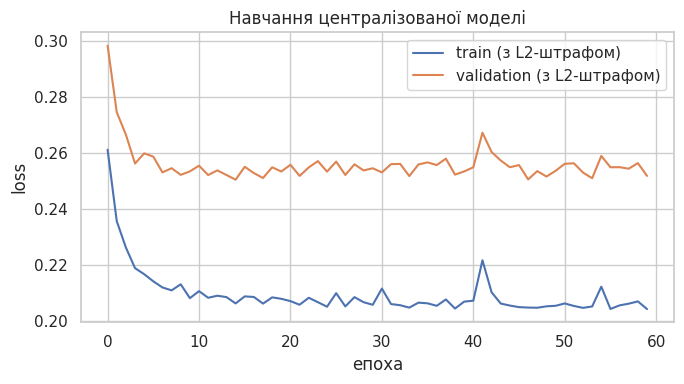

,accuracy,macro_f1,balanced_acc,log_loss
Централізована (Global Test),0.9178,0.9300,0.9305,0.2286


In [20]:
# Фінальна централізована модель: весь FL Train Pool, обрані гіперпараметри
central = SoftmaxRegression(d, C, lam=LAM)
hist_c = central.fit(X_pool, Y_pool, epochs=EPOCHS, lr=LR, batch_size=BS, X_val=X_val, Y_val=Y_val)

plt.figure(figsize=(7, 4))
plt.plot(hist_c['train_loss'], label='train (з L2-штрафом)')
plt.plot(hist_c['val_loss'], label='validation (з L2-штрафом)')
plt.xlabel('епоха'); plt.ylabel('loss'); plt.title('Навчання централізованої моделі'); plt.legend()
plt.tight_layout(); plt.show()

res_central = evaluate(central, X_test, y_test)     # ЄДИНЕ використання Global Test для цієї моделі
pd.DataFrame([res_central], index=['Централізована (Global Test)'])

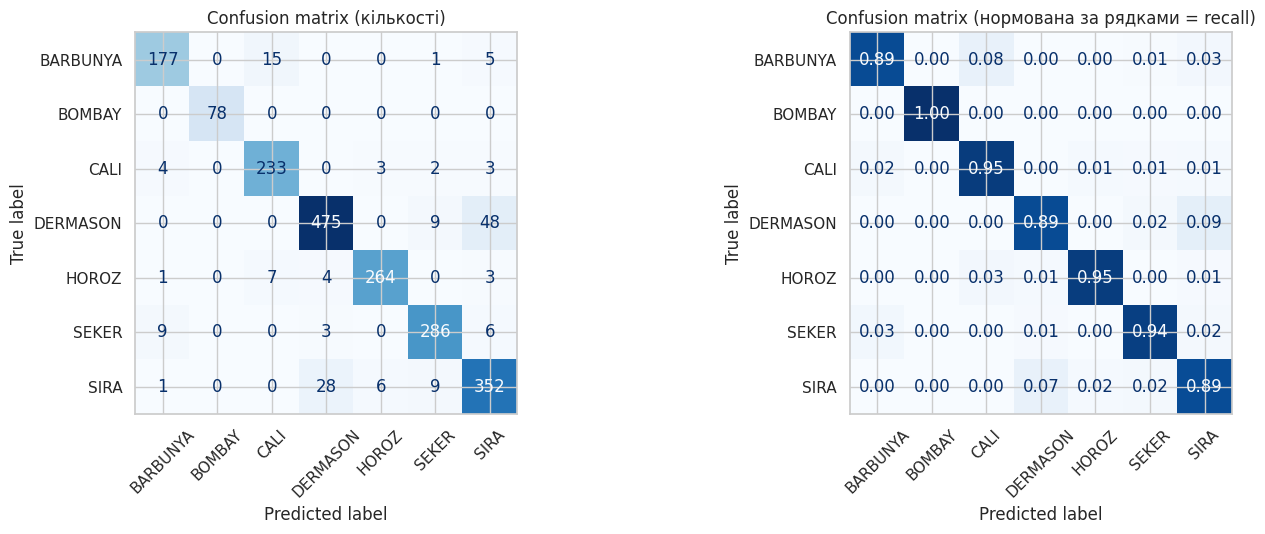

F1 по класах: {'BARBUNYA': np.float64(0.908), 'BOMBAY': np.float64(1.0), 'CALI': np.float64(0.932), 'DERMASON': np.float64(0.912), 'HOROZ': np.float64(0.957), 'SEKER': np.float64(0.936), 'SIRA': np.float64(0.866)}


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
cm = confusion_matrix(y_test, central.predict(X_test))
ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(ax=axes[0], cmap='Blues', colorbar=False, xticks_rotation=45)
axes[0].set_title('Confusion matrix (кількості)')
ConfusionMatrixDisplay(cm / cm.sum(1, keepdims=True), display_labels=CLASSES).plot(
    ax=axes[1], cmap='Blues', colorbar=False, xticks_rotation=45, values_format='.2f')
axes[1].set_title('Confusion matrix (нормована за рядками = recall)')
plt.tight_layout(); plt.show()

print('F1 по класах:', dict(zip(CLASSES, f1_score(y_test, central.predict(X_test), average=None).round(3))))

**Навчання та результат на Global Test.** Train і validation loss монотонно спадають і майже збігаються — ні перенавчання, ні недонавчання; до 60-ї епохи криві вийшли на плато.

**Global Test:** accuracy **0.918**, macro-F1 **0.930**, balanced accuracy **0.931**, log-loss **0.229**. Результати на тесті близькі до валідаційних, тобто вибір гіперпараметрів не «підігнаний» під валідацію.

**Confusion matrix:**
- BOMBAY класифікується ідеально (F1 = 1.0) — він набагато більший за інші сорти;
- основна плутанина — **SIRA ↔ DERMASON** (найнижчий F1 = 0.87 у SIRA) та **BARBUNYA ↔ CALI**; саме ці пари найбільше перекривались на boxplot-ах. Межі між ними нелінійні, тому лінійна модель тут упирається у свою стелю.
- macro-F1 і balanced accuracy навіть трохи вищі за accuracy: рідкісні класи (BOMBAY) розпізнаються добре, а помилки зосереджені у великих класах (DERMASON, SIRA).

Ця модель — **базова лінія** для порівняння з федеративними.

In [22]:
# Допоміжна перевірка (не основний результат): sklearn з еквівалентною регуляризацією.
# Наша ціль: (1/m)ΣCE + λ/2||W||²  <=>  sklearn: C·ΣCE + 1/2||W||²  при C = 1/(λm)
from sklearn.linear_model import LogisticRegression
sk = LogisticRegression(C=1 / (max(LAM, 1e-8) * len(X_pool)), max_iter=5000).fit(X_pool, y_pool)
P_sk = sk.predict_proba(X_val)
print(f'sklearn val acc={accuracy_score(y_val, P_sk.argmax(1)):.4f}, log-loss={log_loss(y_val, P_sk):.4f}')
print(f'наша    val acc={evaluate(central, X_val, y_val)["accuracy"]:.4f}, log-loss={evaluate(central, X_val, y_val)["log_loss"]:.4f}')

sklearn val acc=0.9227, log-loss=0.2288
наша    val acc=0.9218, log-loss=0.2305


*Допоміжна перевірка, не основний результат.* `sklearn.LogisticRegression` з еквівалентною ціллю ($C = 1/(\lambda m)$, при $\lambda=0$ — практично без регуляризації) дає на валідації accuracy 0.9227 / log-loss 0.2288 проти наших 0.9218 / 0.2305. Точний розв'язувач (L-BFGS) знаходить мінімум трохи точніше, ніж 60 епох SGD, але різниця мізерна — наша реалізація збігається до того самого розв'язку.

---
## Етап 4. Розподіл даних між клієнтами та сервером

### 4.1 Архітектура та права доступу

```
                  ┌──────────────────────── СЕРВЕР (агрегатор) ────────────────────────┐
                  │  Global Validation (моніторинг, гіперпараметри)                     │
                  │  Global Test (лише фінальна оцінка)                                 │
                  │  глобальна модель w^t = (W, b);   FedAvg-агрегація                  │
                  └──────▲───────────────────────────────▲───────────────────────▲──────┘
            w^t ↓  w_k^{t+1}, n_k ↑          w^t ↓  w_k^{t+1}, n_k ↑        (лише параметри
                  ┌──────┴──────┐                 ┌──────┴──────┐           та n_k)
                  │  Клієнт 1   │       ...       │  Клієнт K   │
                  │  D_1 (сирі  │                 │  D_K (сирі  │
                  │  дані)      │                 │  дані)      │
                  └─────────────┘                 └─────────────┘
```

- **Сервер** бачить лише Global Validation, Global Test, параметри моделей від клієнтів і $n_k$ (для зважування та для агрегації статистик масштабування). Сирих даних клієнтів не бачить.
- **Клієнт** бачить лише власний $D_k$ і глобальну модель, яку надсилає сервер. Не бачить Global Test / Validation, дані й моделі інших клієнтів.

У коді це відображено класами `Client` (дані лежать у приватних полях, назовні — лише `local_train`, що повертає параметри та $n_k$) і `Server` (працює тільки з цим інтерфейсом).

### 4.2 Методика розподілу FL Train Pool

- **IID:** стратифіковане розбиття на $K$ рівних частин (`StratifiedKFold`, тестові фолди) — кожен клієнт отримує ~однакову кількість прикладів з глобальними пропорціями класів.
- **Non-IID (Діріхле):** для кожного класу $c$ генеруємо $(p_{1c},\dots,p_{Kc})\sim\text{Dir}(\alpha,\dots,\alpha)$ і ділимо приклади класу $c$ між клієнтами у цих пропорціях. Чим менше $\alpha$, тим більше маси концентрується в одному-двох клієнтах.

Основна конфігурація: **K = 5**, сценарії IID, $\alpha\in\{5, 1, 0.3\}$ та додатково $\alpha=0.1$ (екстремальна неоднорідність). Зерно фіксоване (`SEED = 42`) → розподіл відтворюваний. Для кожного сценарію автоматично перевіряється, що кожен приклад належить рівно одному клієнту, і шукаються клієнти з $n_k<10$.

In [23]:
def partition_iid(y, K, seed=SEED):
    """IID: стратифіковане розбиття на K приблизно рівних частин."""
    skf = StratifiedKFold(n_splits=K, shuffle=True, random_state=seed)
    return [test_idx for _, test_idx in skf.split(np.zeros(len(y)), y)]

def partition_dirichlet(y, K, alpha, seed=SEED):
    """Non-IID: для кожного класу c пропорції (p_1c..p_Kc) ~ Dir(α,...,α)."""
    rng = np.random.default_rng(seed)
    parts = [[] for _ in range(K)]
    for c in np.unique(y):
        idx_c = rng.permutation(np.where(y == c)[0])
        p = rng.dirichlet(alpha * np.ones(K))
        cuts = (np.cumsum(p) * len(idx_c)).astype(int)[:-1]
        for k, chunk in enumerate(np.split(idx_c, cuts)):
            parts[k].extend(chunk.tolist())
    return [np.array(sorted(p_), dtype=int) for p_ in parts]

def partition_table(parts, y):
    tab = pd.DataFrame([np.bincount(y[p], minlength=C) for p in parts],
                       index=[f'client {k}' for k in range(len(parts))], columns=CLASSES)
    tab['n_k'] = tab.sum(axis=1)
    tab['класів'] = (tab[CLASSES] > 0).sum(axis=1)
    return tab

def check_partition(parts, y, name):
    allidx = np.concatenate(parts)
    assert len(allidx) == len(y) and len(np.unique(allidx)) == len(y), 'кожен приклад рівно в одного клієнта!'
    small = [k for k, p in enumerate(parts) if len(p) < 10]
    print(f'{name}: OK (кожен приклад рівно в одного клієнта), клієнтів з n_k<10: {small if small else "немає"}')

K = 5
SCENARIOS = {'IID': partition_iid(y_pool, K)}
for a in [5, 1, 0.3, 0.1]:
    SCENARIOS[f'α={a}'] = partition_dirichlet(y_pool, K, a, seed=SEED)

for name, parts in SCENARIOS.items():
    check_partition(parts, y_pool, name)

IID: OK (кожен приклад рівно в одного клієнта), клієнтів з n_k<10: немає
α=5: OK (кожен приклад рівно в одного клієнта), клієнтів з n_k<10: немає
α=1: OK (кожен приклад рівно в одного клієнта), клієнтів з n_k<10: немає
α=0.3: OK (кожен приклад рівно в одного клієнта), клієнтів з n_k<10: немає
α=0.1: OK (кожен приклад рівно в одного клієнта), клієнтів з n_k<10: [3]


In [24]:
for name in ['IID', 'α=1', 'α=0.3']:
    print(f'\n=== {name} ===')
    display(partition_table(SCENARIOS[name], y_pool))


=== IID ===


,BARBUNYA,BOMBAY,CALI,DERMASON,HOROZ,SEKER,SIRA,n_k,класів
client 0,185,74,228,497,260,283,369,1896,7
client 1,185,73,228,497,260,284,369,1896,7
client 2,185,73,228,496,261,284,369,1896,7
client 3,185,73,228,496,261,284,369,1896,7
client 4,186,73,228,496,260,284,368,1895,7



=== α=1 ===


,BARBUNYA,BOMBAY,CALI,DERMASON,HOROZ,SEKER,SIRA,n_k,класів
client 0,317,34,52,992,196,168,56,1815,7
client 1,3,9,62,989,105,72,32,1272,7
client 2,297,71,1,176,564,253,1294,2656,7
client 3,281,127,764,136,368,710,110,2496,7
client 4,28,125,261,189,69,216,352,1240,7



=== α=0.3 ===


,BARBUNYA,BOMBAY,CALI,DERMASON,HOROZ,SEKER,SIRA,n_k,класів
client 0,83,132,0,206,960,124,0,1505,5
client 1,0,25,205,38,0,1096,172,1536,5
client 2,813,2,245,57,29,138,32,1316,7
client 3,7,138,54,0,5,0,842,1046,5
client 4,23,69,636,2181,308,61,798,4076,7


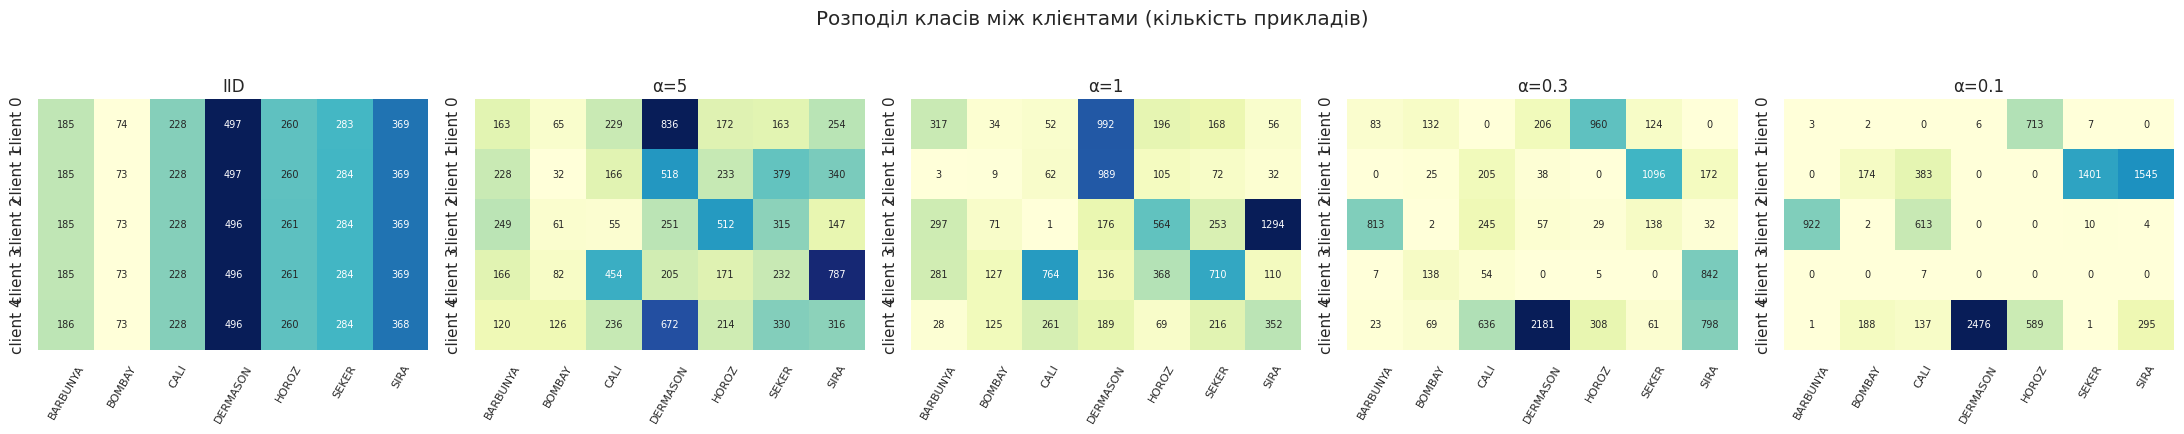

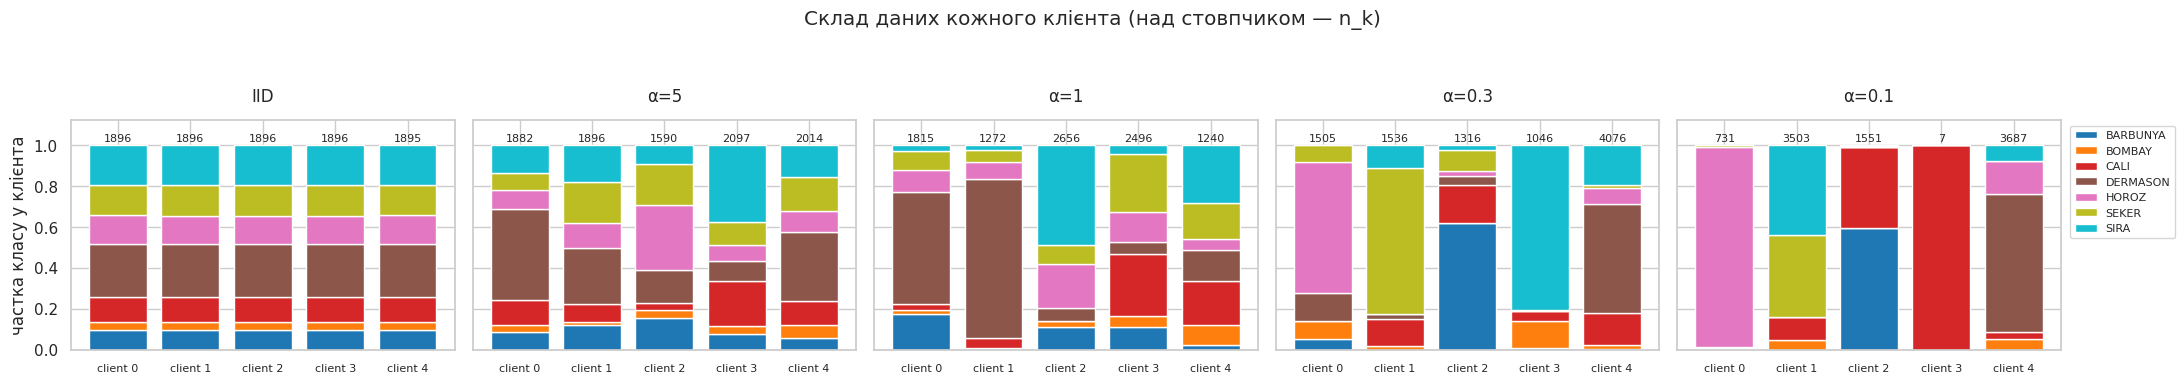

In [25]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4.2))
for ax, (name, parts) in zip(axes, SCENARIOS.items()):
    tab = partition_table(parts, y_pool)[CLASSES]
    sns.heatmap(tab, annot=True, fmt='d', cmap='YlGnBu', cbar=False, ax=ax, annot_kws={'size': 7})
    ax.set_title(name); ax.tick_params(axis='x', rotation=60, labelsize=8)
plt.suptitle('Розподіл класів між клієнтами (кількість прикладів)', y=1.03)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 5, figsize=(22, 3.6), sharey=True)
for ax, (name, parts) in zip(axes, SCENARIOS.items()):
    tab = partition_table(parts, y_pool)
    (tab[CLASSES].div(tab['n_k'], axis=0)).plot.bar(stacked=True, ax=ax, legend=False, width=0.8, colormap='tab10')
    for i, n in enumerate(tab['n_k']):
        ax.text(i, 1.02, str(n), ha='center', fontsize=8)
    ax.set_title(name, pad=14); ax.set_ylim(0, 1.12); ax.tick_params(axis='x', rotation=0, labelsize=8)
axes[0].set_ylabel('частка класу у клієнта')
axes[-1].legend(CLASSES, bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=8)
plt.suptitle('Склад даних кожного клієнта (над стовпчиком — n_k)', y=1.06)
plt.tight_layout(); plt.show()

**Що показано:** таблиці та теплові карти кількості прикладів кожного класу в кожного клієнта, а також склад даних клієнтів у частках (над стовпчиками — $n_k$).

**Закономірності:**
- **IID:** 1895–1896 прикладів у кожного, пропорції класів однакові й дорівнюють глобальним.
- **α = 5:** розміри 1590–2097, пропорції помітно, але помірно відрізняються.
- **α = 1:** розміри 1240–2656; у клієнта 1 78% даних — DERMASON і лише 3 BARBUNYA; у клієнта 2 — 1 приклад CALI.
- **α = 0.3:** у трьох клієнтів з п'яти **немає 2 класів з 7**; клієнт 1 на 71% складається з SEKER, клієнт 3 — на 80% з SIRA; розміри від 1046 до 4076.
- **α = 0.1:** майже «один клас на клієнта», а **клієнт 3 має лише 7 прикладів** (менше 10) — усі одного сорту CALI. Такий клієнт майже нічого не може навчити самостійно, а в простому середньому ваг мав би ту саму вагу, що й клієнт з 3.5 тис. прикладів.

**Як це впливає на глобальну модель:** кожен клієнт мінімізує *свою* функцію втрат, оптимум якої зсунутий у бік його домінуючих класів (bias $b$ завищує частий клас, ваги для відсутніх класів лише «відштовхуються» і ніколи не отримують позитивного сигналу). Локальні моделі тягнуть глобальну в різні боки, їх середнє вже не є оптимумом загальної задачі — чим менше α, тим більший цей зсув і тим повільніша й гірша збіжність. Перевіряємо це в Етапі 6.

---
## Етап 5. Симуляція федеративного навчання (FedAvg)

Алгоритм у методі `Server.run`:
1. сервер ініціалізує $w^0$;
2. на раунді $t$ обирає підмножину клієнтів $S_t$ (параметр `frac`; у наших експериментах `frac = 1` — усі клієнти);
3. розсилає $w^t$;
4. кожен клієнт $k\in S_t$ робить $E$ локальних епох міні-батчевого SGD, стартуючи з $w^t$;
5. повертає $w_k^{t+1}$ та $n_k$;
6. сервер агрегує: $w^{t+1}=\sum_{k\in S_t}\frac{n_k}{\sum_{j\in S_t}n_j}w_k^{t+1}$ окремо для $W$ і $b$;
7. оцінює $w^{t+1}$ на Global Validation.

Додатково на кожному раунді фіксується **client drift** — середня відстань $\frac1{|S_t|}\sum_k\|W_k^{t+1}-W^{t+1}\|_F$ між локальними моделями та новою глобальною.

Гіперпараметри локального навчання беремо з Етапу 3 (`lr = 0.5`, `batch = 32`, `λ = 0`); кількість раундів — 40.

In [26]:
class Client:
    """Клієнт: тримає ЛИШЕ свої дані. Назовні віддає тільки параметри моделі та n_k."""
    def __init__(self, cid, X, y):
        self.cid = cid
        self._X, self._Y = X, one_hot(y, C)          # приватні дані, сервер їх не читає
        self.n = len(X)

    def local_train(self, global_params, E, lr, batch_size, lam, seed):
        model = SoftmaxRegression(self._X.shape[1], C, lam=lam)
        model.set_params(global_params)               # старт з глобальної моделі w^t
        model.fit(self._X, self._Y, epochs=E, lr=lr, batch_size=batch_size, seed=seed)
        return model.get_params(), self.n


class Server:
    """Сервер: ініціалізує та агрегує модель, оцінює її на Global Validation / Global Test."""
    def __init__(self, clients, n_features, lam, X_val, y_val, seed=SEED):
        self.clients = clients
        self.model = SoftmaxRegression(n_features, C, lam=lam, seed=seed)   # w^0
        self.lam, self.X_val, self.y_val = lam, X_val, y_val
        self.rng = np.random.default_rng(seed)

    @staticmethod
    def aggregate(results, weighted=True):
        """FedAvg: w^{t+1} = Σ_k n_k / Σ_j n_j · w_k^{t+1} (окремо для W і b)."""
        n = np.array([nk for _, nk in results], dtype=float)
        coef = n / n.sum() if weighted else np.full(len(results), 1 / len(results))
        return {key: sum(c * p[key] for c, (p, _) in zip(coef, results)) for key in ('W', 'b')}

    def run(self, rounds, E, lr, batch_size, frac=1.0, weighted=True, verbose=False):
        hist = {'val_loss': [], 'val_acc': [], 'val_macro_f1': [], 'drift': []}
        for t in range(rounds):
            # 2) вибір підмножини клієнтів S_t
            m_sel = max(1, int(round(frac * len(self.clients))))
            S_t = self.rng.choice(len(self.clients), m_sel, replace=False)
            # 3–5) розсилка w^t, локальне навчання, повернення w_k^{t+1}
            w_t = self.model.get_params()
            results = [self.clients[k].local_train(w_t, E, lr, batch_size, self.lam, seed=SEED + 1000 * t + k)
                       for k in S_t]
            # 6) агрегація
            new = self.aggregate(results, weighted)
            # client drift: середня відстань локальних моделей від нової глобальної
            hist['drift'].append(np.mean([np.linalg.norm(p['W'] - new['W']) for p, _ in results]))
            self.model.set_params(new)
            # 7) оцінка на Global Validation
            met = evaluate(self.model, self.X_val, self.y_val)
            hist['val_loss'].append(met['log_loss']); hist['val_acc'].append(met['accuracy'])
            hist['val_macro_f1'].append(met['macro_f1'])
            if verbose and (t % 10 == 0 or t == rounds - 1):
                print(f'round {t:3d} | val acc {met["accuracy"]:.4f} | macro-F1 {met["macro_f1"]:.4f} | log-loss {met["log_loss"]:.4f}')
        return hist


def make_clients(parts, X=X_pool, y=y_pool):
    return [Client(k, X[p], y[p]) for k, p in enumerate(parts)]

def train_local_models(parts, epochs=EPOCHS):
    """Моделі, навчені ЛИШЕ на даних окремого клієнта (без обміну)."""
    out = []
    for k, p in enumerate(parts):
        m = SoftmaxRegression(d, C, lam=LAM)
        m.fit(X_pool[p], one_hot(y_pool[p], C), epochs=epochs, lr=LR, batch_size=BS, seed=SEED + k)
        out.append(m)
    return out

ROUNDS = 40

round   0 | val acc 0.9144 | macro-F1 0.9223 | log-loss 0.2945


round  10 | val acc 0.9218 | macro-F1 0.9302 | log-loss 0.2385


round  20 | val acc 0.9218 | macro-F1 0.9305 | log-loss 0.2346


round  30 | val acc 0.9227 | macro-F1 0.9315 | log-loss 0.2321


round  39 | val acc 0.9208 | macro-F1 0.9297 | log-loss 0.2324


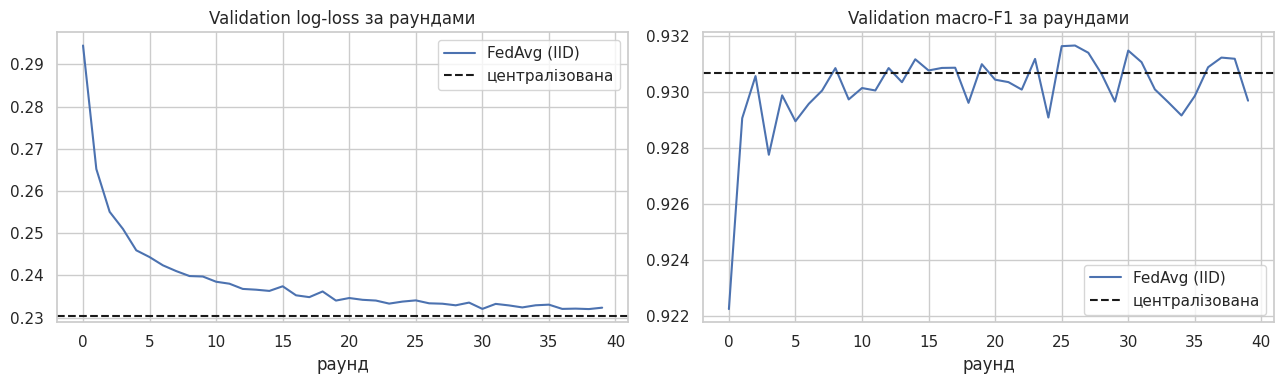

In [27]:
# Базовий запуск FedAvg: IID, K=5, E=5
server = Server(make_clients(SCENARIOS['IID']), d, LAM, X_val, y_val)
hist_iid = server.run(ROUNDS, E=5, lr=LR, batch_size=BS, verbose=True)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(hist_iid['val_loss'], label='FedAvg (IID)')
axes[0].axhline(evaluate(central, X_val, y_val)['log_loss'], ls='--', c='k', label='централізована')
axes[0].set_title('Validation log-loss за раундами'); axes[0].set_xlabel('раунд'); axes[0].legend()
axes[1].plot(hist_iid['val_macro_f1'], label='FedAvg (IID)')
axes[1].axhline(evaluate(central, X_val, y_val)['macro_f1'], ls='--', c='k', label='централізована')
axes[1].set_title('Validation macro-F1 за раундами'); axes[1].set_xlabel('раунд'); axes[1].legend()
plt.tight_layout(); plt.show()

**Що показано:** базовий запуск FedAvg (IID, K = 5, E = 5) — якість на валідації за раундами порівняно з централізованою моделлю.

**Закономірність:** вже після 1-го раунду macro-F1 0.922, після ~10 раундів крива виходить на плато, практично на рівні централізованої моделі (val macro-F1 ≈ 0.930).

**Чому:** при IID кожен клієнт мінімізує по суті ту саму функцію втрат, що й централізована модель, тож їхні оновлення спрямовані в один бік, а усереднення лише зменшує шум SGD. Для опуклої задачі FedAvg на IID-даних збігається до того ж оптимуму. Дрібні коливання кривої — наслідок стохастичності локального SGD з великим `lr`.

---
## Етап 6. Дослідження ефектів федеративного навчання

Порівнюємо на Global Test три типи моделей:
1. **локальні** — кожна навчена лише на $D_k$ (60 епох, ті самі гіперпараметри, без обміну);
2. **глобальна** — після 40 раундів FedAvg (E = 5);
3. **централізована** — з Етапу 3.

In [28]:
def run_scenario(parts, E=5, rounds=ROUNDS, weighted=True, frac=1.0):
    srv = Server(make_clients(parts), d, LAM, X_val, y_val)
    h = srv.run(rounds, E=E, lr=LR, batch_size=BS, weighted=weighted, frac=frac)
    return srv.model, h

E_BASE = 5
exp1 = {}
for name, parts in SCENARIOS.items():
    g_model, h = run_scenario(parts, E=E_BASE)
    locals_ = train_local_models(parts)
    exp1[name] = {'global': g_model, 'hist': h, 'locals': locals_}

# Таблиця на Global Test: локальні, глобальна, централізована
rows = []
for name, r in exp1.items():
    for k, lm in enumerate(r['locals']):
        rows.append({'сценарій': name, 'модель': f'локальна client {k}', 'n_k': len(SCENARIOS[name][k]),
                     **evaluate(lm, X_test, y_test)})
    rows.append({'сценарій': name, 'модель': 'ГЛОБАЛЬНА (FedAvg)', 'n_k': len(X_pool), **evaluate(r['global'], X_test, y_test)})
rows.append({'сценарій': '—', 'модель': 'ЦЕНТРАЛІЗОВАНА', 'n_k': len(X_pool), **res_central})
cmp_full = pd.DataFrame(rows)
cmp_full

,сценарій,модель,n_k,accuracy,macro_f1,balanced_acc,log_loss
0,IID,локальна client 0,1896,0.9139,0.9265,0.9269,0.2487
1,IID,локальна client 1,1896,0.9168,0.9285,0.9289,0.2359
2,IID,локальна client 2,1896,0.9158,0.9276,0.9266,0.2376
3,IID,локальна client 3,1896,0.9163,0.9274,0.9281,0.2484
4,IID,локальна client 4,1895,0.9099,0.9225,0.9213,0.2497
5,IID,ГЛОБАЛЬНА (FedAvg),9479,0.9163,0.9281,0.9275,0.2301
6,α=5,локальна client 0,1882,0.9119,0.9236,0.9209,0.2677
7,α=5,локальна client 1,1896,0.9158,0.9274,0.9275,0.2435
8,α=5,локальна client 2,1590,0.8976,0.9100,0.9154,0.2865
9,α=5,локальна client 3,2097,0.8942,0.9145,0.9151,0.2848


In [29]:
# Компактне зведення
summary = []
for name, r in exp1.items():
    loc = cmp_full[(cmp_full['сценарій'] == name) & cmp_full['модель'].str.startswith('локальна')]
    g = cmp_full[(cmp_full['сценарій'] == name) & (cmp_full['модель'] == 'ГЛОБАЛЬНА (FedAvg)')].iloc[0]
    summary.append({'сценарій': name,
                    'глоб. accuracy': g['accuracy'], 'глоб. macro-F1': g['macro_f1'],
                    'глоб. bal.acc': g['balanced_acc'], 'глоб. log-loss': g['log_loss'],
                    'лок. macro-F1 (сер.)': loc['macro_f1'].mean(),
                    'лок. macro-F1 (min)': loc['macro_f1'].min(), 'лок. macro-F1 (max)': loc['macro_f1'].max()})
summary = pd.DataFrame(summary).set_index('сценарій')
summary.loc['централізована'] = [res_central['accuracy'], res_central['macro_f1'],
                                 res_central['balanced_acc'], res_central['log_loss'], np.nan, np.nan, np.nan]
summary

,глоб. accuracy,глоб. macro-F1,глоб. bal.acc,глоб. log-loss,лок. macro-F1 (сер.),лок. macro-F1 (min),лок. macro-F1 (max)
сценарій,,,,,,,
IID,0.9163,0.9281,0.9275,0.2301,0.9265,0.9225,0.9285
α=5,0.9168,0.9284,0.9284,0.2296,0.9191,0.9100,0.9274
α=1,0.9119,0.9244,0.9268,0.2367,0.8499,0.7292,0.9073
α=0.3,0.9168,0.9280,0.9272,0.2450,0.6809,0.5382,0.8919
α=0.1,0.8789,0.8933,0.8928,0.3283,0.4141,0.0715,0.6149
централізована,0.9178,0.9300,0.9305,0.2286,NaN,NaN,NaN


**Що показано:** повна таблиця (кожна локальна модель, глобальна, централізована) та компактне зведення.

**Закономірності:**
- **Централізована** — верхня межа: macro-F1 0.930, log-loss 0.229.
- **Глобальна FedAvg** при IID, α = 5, α = 1 і навіть α = 0.3 майже не поступається централізованій (macro-F1 0.924–0.928, різниця ≤ 0.6 п.п.), але її **log-loss** зростає зі зменшенням α: 0.230 → 0.237 → 0.245. При α = 0.1 глобальна модель помітно гірша: macro-F1 0.893, log-loss 0.328.
- **Локальні** моделі деградують значно швидше: середній macro-F1 0.927 (IID) → 0.850 (α = 1) → 0.681 (α = 0.3) → 0.414 (α = 0.1). Клієнт 3 при α = 0.1 (7 прикладів одного класу) має macro-F1 0.07 — він просто завжди передбачає CALI. Їх log-loss доходить до 5–6, бо модель упевнено дає ~0 ймовірності класам, яких ніколи не бачила.

**Висновок:** навіть при сильній неоднорідності федеративна модель у рази краща за середню локальну — це і є головна користь FL: клієнти отримують модель, що «знає» всі класи, не обмінюючись даними.

### Експеримент 1. Вплив неоднорідності даних (α)

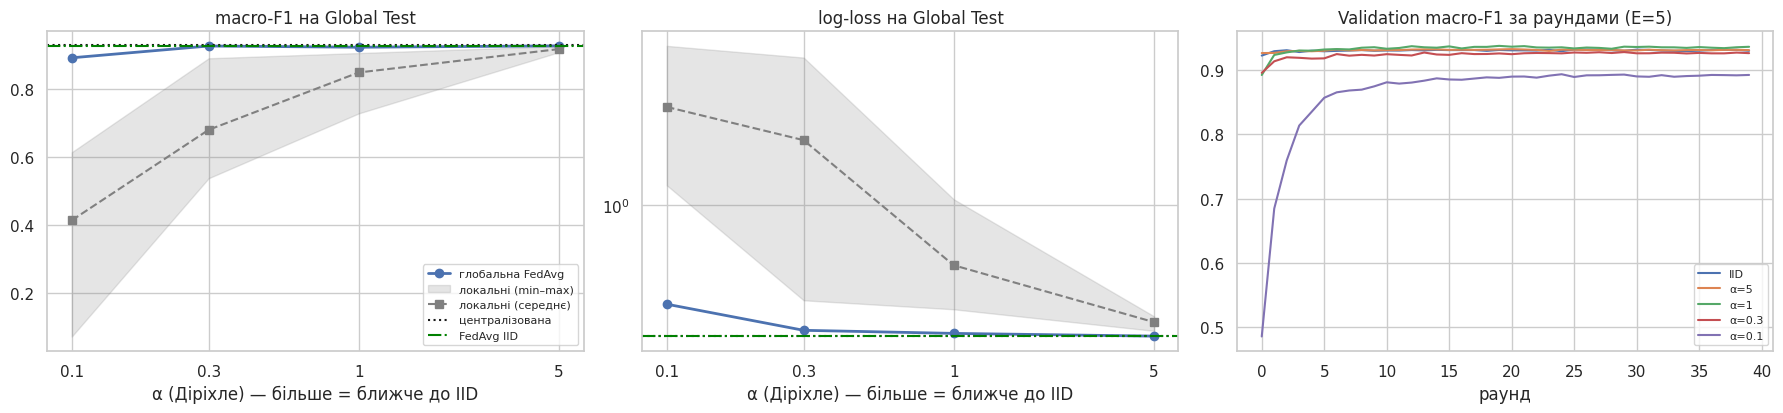

In [30]:
alphas = [0.1, 0.3, 1, 5]
names = [f'α={a}' for a in alphas]

fig, axes = plt.subplots(1, 3, figsize=(18, 4.3))
for metric, ax, title in [('macro_f1', axes[0], 'macro-F1'), ('log_loss', axes[1], 'log-loss')]:
    g_vals = [evaluate(exp1[n]['global'], X_test, y_test)[metric] for n in names]
    l_vals = np.array([[evaluate(m, X_test, y_test)[metric] for m in exp1[n]['locals']] for n in names])
    ax.plot(alphas, g_vals, 'o-', lw=2, label='глобальна FedAvg')
    ax.fill_between(alphas, l_vals.min(1), l_vals.max(1), alpha=.2, color='gray', label='локальні (min–max)')
    ax.plot(alphas, l_vals.mean(1), 's--', color='gray', label='локальні (середнє)')
    ax.axhline(res_central[metric], ls=':', c='k', label='централізована')
    ax.axhline(evaluate(exp1['IID']['global'], X_test, y_test)[metric], ls='-.', c='green', label='FedAvg IID')
    ax.set_xscale('log'); ax.set_xticks(alphas); ax.set_xticklabels(alphas)
    ax.set_xlabel('α (Діріхле) — більше = ближче до IID'); ax.set_title(f'{title} на Global Test')
axes[0].legend(fontsize=8)
axes[1].set_yscale('log')
for n in ['IID'] + names[::-1]:
    axes[2].plot(exp1[n]['hist']['val_macro_f1'], label=n)
axes[2].set_title('Validation macro-F1 за раундами (E=5)'); axes[2].set_xlabel('раунд'); axes[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Що показано:** якість глобальної моделі на Global Test як функція α (синя лінія), діапазон і середнє локальних моделей (сіре), рівні централізованої моделі та FedAvg-IID; праворуч — навчання за раундами.

**Закономірність:** при α ≥ 0.3 глобальна модель тримається біля рівня централізованої, при α = 0.1 — різке падіння (macro-F1 −3.7 п.п., log-loss +43%). Криві за раундами: при α = 0.1 модель стартує з macro-F1 ≈ 0.5 і навіть через 40 раундів виходить на плато ≈ 0.89, помітно нижче за інші сценарії. Локальні моделі падають зі зменшенням α набагато крутіше, ніж глобальна.

**Чому Non-IID погіршує FL.** Для кожного клієнта оптимум локальної втрати $J_k$ не збігається з оптимумом глобальної $J=\sum_k\frac{n_k}{n}J_k$. За кілька локальних епох кожен клієнт «з'їжджає» до свого оптимуму (перекошений bias, ваги для відсутніх класів лише зменшуються), і середнє таких зсунутих моделей — вже **не оптимум** $J$, а зміщена точка. До того ж градієнти клієнтів суперечать один одному, тому збіжність повільніша й шумніша. Логістична регресія — опукла, проста модель, тож вона досить стійка до цього ефекту, і для α ≥ 0.3 втрати малі; при α = 0.1 зсув стає суттєвим.

**Чи може глобальна модель бути гіршою за централізовану?** Так — у всіх наших сценаріях вона не краща, а при α = 0.1 гірша помітно. Централізована модель мінімізує саме $J$ по всіх даних одразу; FedAvg лише наближає цей оптимум через усереднення локально зміщених моделей, і з неоднорідністю наближення погіршується.

**Чи може глобальна модель бути гіршою за деякі локальні?** Так. (1) На Global Test при IID локальна модель клієнта 1 має macro-F1 0.9285 проти 0.9281 у глобальної — при IID кожен клієнт і сам має репрезентативну вибірку, а глобальна модель несе шум від усереднення, тож різниця в межах шуму може бути на будь-чию користь. (2) Набагато важливіше — **на власному розподілі клієнта**: при Non-IID локальна модель, спеціалізована на своїх 5 класах, може перевершити глобальну, яка «розмита» між усіма клієнтами. Це прямо видно в Експерименті Б (персоналізація): при α = 0.3 чисто локальні моделі на локальних тестах мають середню accuracy 0.962 проти 0.928 у глобальної.

### Експеримент 2. Вплив кількості локальних епох E

Порівнюємо E ∈ {1, 5, 10} для IID, α = 0.3 та додатково α = 0.1 (де ефект видно найчіткіше). Кількість раундів однакова (40), тому більше E = більше обчислень; щоб порівняти чесно, в таблиці є також стан **при однаковому бюджеті — 40 сумарних локальних епох** (40 раундів E = 1 проти 8 раундів E = 5 проти 4 раундів E = 10).

In [31]:
exp2 = {}
E2_SCEN = ['IID', 'α=0.3', 'α=0.1']
for scen in E2_SCEN:
    for E in [1, 5, 10]:
        g_model, h = run_scenario(SCENARIOS[scen], E=E)
        exp2[(scen, E)] = {'model': g_model, 'hist': h, 'test': evaluate(g_model, X_test, y_test)}

e2_tab = pd.DataFrame({f'{s}, E={E}': r['test'] for (s, E), r in exp2.items()}).T
e2_tab['final drift'] = [r['hist']['drift'][-1] for r in exp2.values()]
# рівний бюджет обчислень: стан після 40 сумарних локальних епох (40 раундів E=1, 8 раундів E=5, 4 раунди E=10)
e2_tab['val macro-F1 @40 епох'] = [r['hist']['val_macro_f1'][40 // E - 1] for (s, E), r in exp2.items()]
e2_tab['val log-loss @40 епох'] = [r['hist']['val_loss'][40 // E - 1] for (s, E), r in exp2.items()]
e2_tab

,accuracy,macro_f1,balanced_acc,log_loss,final drift,val macro-F1 @40 епох,val log-loss @40 епох
"IID, E=1",0.9158,0.9286,0.9282,0.2363,0.2971,0.9302,0.2404
"IID, E=5",0.9163,0.9281,0.9275,0.2301,0.7830,0.9301,0.2410
"IID, E=10",0.9188,0.9311,0.9317,0.2289,1.1386,0.9317,0.2411
"α=0.3, E=1",0.9129,0.9236,0.9213,0.2496,0.9686,0.9227,0.2513
"α=0.3, E=5",0.9168,0.9280,0.9272,0.2450,1.6174,0.9221,0.2615
"α=0.3, E=10",0.9178,0.9294,0.9280,0.2426,1.9235,0.9232,0.2617
"α=0.1, E=1",0.9045,0.9172,0.9161,0.2655,1.0328,0.9102,0.2652
"α=0.1, E=5",0.8789,0.8933,0.8928,0.3283,1.6733,0.8680,0.3734
"α=0.1, E=10",0.8720,0.8851,0.8844,0.3547,2.0403,0.8023,0.5165


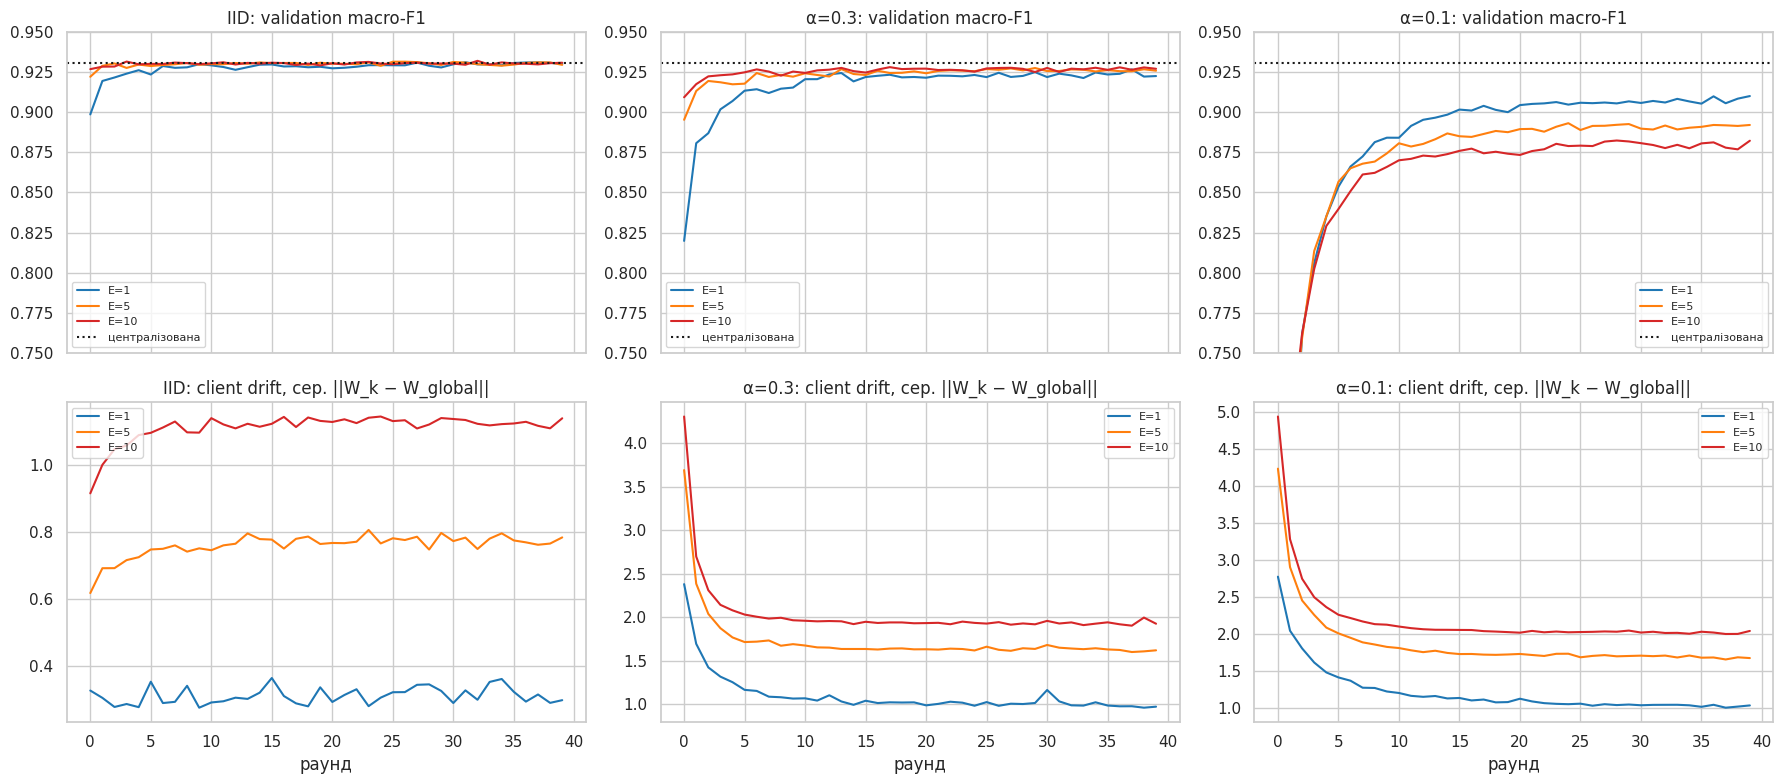

In [32]:
colors = {1: 'tab:blue', 5: 'tab:orange', 10: 'tab:red'}
fig, axes = plt.subplots(2, 3, figsize=(18, 8), sharex=True)
for j, scen in enumerate(E2_SCEN):
    for E in [1, 5, 10]:
        h = exp2[(scen, E)]['hist']
        axes[0, j].plot(h['val_macro_f1'], color=colors[E], label=f'E={E}')
        axes[1, j].plot(h['drift'], color=colors[E], label=f'E={E}')
    axes[0, j].axhline(evaluate(central, X_val, y_val)['macro_f1'], ls=':', c='k', label='централізована')
    axes[0, j].set_title(f'{scen}: validation macro-F1'); axes[0, j].set_ylim(0.75, 0.95)
    axes[1, j].set_title(f'{scen}: client drift, сер. ||W_k − W_global||'); axes[1, j].set_xlabel('раунд')
    axes[0, j].legend(fontsize=8); axes[1, j].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Що показано:** фінальні метрики на Global Test, якість при рівному бюджеті епох, валідаційний macro-F1 за раундами (вгорі) та client drift (внизу).

**Client drift (клієнтський дрейф)** — явище, коли під час локального навчання моделі клієнтів відходять від глобальної моделі в напрямку власних локальних оптимумів, і тим далі, чим довше вони навчаються без синхронізації. Коли дані Non-IID, ці напрямки різні й систематичні, тож відхилення не взаємно компенсуються при усередненні, а зсувають глобальну модель.

**Закономірності:**
- Drift завжди зростає з E: IID 0.30 → 0.78 → 1.14; α = 0.1 1.03 → 1.67 → 2.04. При Non-IID він у 2–3 рази більший, ніж при IID, за того самого E.
- **IID:** більше E майже нічого не змінює (macro-F1 0.929 / 0.928 / 0.931) — дрейф при IID це лише шум SGD, який усереднення гасить.
- **α = 0.3:** фінальна якість з ростом E навіть трохи зростає (0.924 → 0.928 → 0.929): 40 раундів з E = 1 — це лише 40 епох, модель ще не дійшла до плато; при рівному бюджеті 40 епох E = 1 вже має найкращий log-loss (0.251 проти 0.262).
- **α = 0.1 — класичний негативний ефект:** macro-F1 0.917 (E = 1) → 0.893 (E = 5) → 0.885 (E = 10), log-loss 0.266 → 0.328 → 0.355. На графіку криві з більшим E виходять на **нижче плато**, і це не лікується додатковими раундами.

**Чому великий E шкодить у Non-IID.** За E епох клієнт з двома класами встигає майже повністю «перенавчитись» під них; з кожною епохою локальна модель ближча до *локального*, а не глобального оптимуму. Отже, FedAvg збігається не до оптимуму $J$, а до зміщеної нерухомої точки, і зсув росте з E. При E = 1 FedAvg близький до звичайного розподіленого SGD, де зсуву майже немає.

**Вплив на вибір гіперпараметрів:** при IID вигідно брати більше E (менше раундів комунікації за ту саму якість); при сильній неоднорідності E треба зменшувати або використовувати методи проти дрейфу (FedProx — проксимальний доданок $\frac\mu2\|w-w^t\|^2$, SCAFFOLD — корекція дрейфу контрольними змінними).

### Додатково: зважене (FedAvg) vs просте середнє ваг

**Питання: чому ваги клієнтів доцільно зважувати за кількістю прикладів? Що буде при простому середньому?**

Глобальна ціль — середня втрата по *всіх прикладах*: $J(w)=\frac1n\sum_{i}\ell_i = \sum_k \frac{n_k}{n}J_k(w)$. Отже, кожен клієнт природно входить з вагою $n_k/n$; при IID і $E=1$ повного батчу зважене середнє оновлень збігається з градієнтним кроком на всіх даних. Просте середнє ($1/K$) оптимізує **іншу** ціль $\frac1K\sum_k J_k$, у якій кожен приклад маленького клієнта «важить» більше, ніж приклад великого: клієнт із 7 прикладами впливає на модель так само, як клієнт із 3500. Це спотворює модель і робить її вразливою до шумних/малих клієнтів.

In [33]:
w_rows = {}
for scen in ['IID', 'α=0.3', 'α=0.1']:
    for weighted in [True, False]:
        g, _ = run_scenario(SCENARIOS[scen], E=E_BASE, weighted=weighted)
        w_rows[f'{scen}, {"зважене (FedAvg)" if weighted else "просте середнє"}'] = evaluate(g, X_test, y_test)
pd.DataFrame(w_rows).T

,accuracy,macro_f1,balanced_acc,log_loss
"IID, зважене (FedAvg)",0.9163,0.9281,0.9275,0.2301
"IID, просте середнє",0.9163,0.9281,0.9275,0.2301
"α=0.3, зважене (FedAvg)",0.9168,0.9280,0.9272,0.2450
"α=0.3, просте середнє",0.9119,0.9259,0.9283,0.2483
"α=0.1, зважене (FedAvg)",0.8789,0.8933,0.8928,0.3283
"α=0.1, просте середнє",0.8932,0.9127,0.9150,0.2958


**Що показано:** порівняння агрегації за $n_k$ і простого середнього.

**Закономірності та пояснення:**
- **IID:** результати ідентичні — усі $n_k$ однакові (1895–1896), тому ваги $n_k/n$ фактично дорівнюють $1/K$.
- **α = 0.3:** зважене краще за accuracy і log-loss, трохи гірше за balanced accuracy — різниця мала.
- **α = 0.1:** просте середнє **виявилось кращим** (macro-F1 0.913 проти 0.893). Це не суперечить теорії, а ілюструє її: зважене середнє чесно оптимізує середню втрату по прикладах, а великі клієнти тут водночас найбільш перекошені за класами. Просте середнє підсилює малих клієнтів, які тримають рідкісні класи, і випадково вирівнює баланс класів — що покращує саме «класово-збалансовані» метрики. Але ціною цього є те, що клієнт із 7 прикладами отримав 20% впливу на модель — у реальній системі такий клієнт міг би бути зашумленим чи зловмисним.

**Висновок:** за замовчуванням правильне зважування за $n_k$ (узгоджене з глобальною ціллю); якщо важлива якість на рідкісних класах/малих клієнтах — це окрема мета (fairness), для якої є спеціальні методи агрегації, а не просте середнє.

---
## Етап 7. Додаткові експерименти (опційно)

### Експеримент А. Вплив кількості клієнтів K ∈ {3, 5, 10}

Для кожного K заново будуємо розбиття (IID, α = 1, α = 0.3), запускаємо FedAvg (E = 5, 40 раундів) і навчаємо локальні моделі.

,K,сценарій,min n_k,глоб. accuracy,глоб. macro_f1,глоб. balanced_acc,глоб. log_loss,лок. macro-F1 (сер.)
0,3,IID,3159,0.9173,0.9299,0.9300,0.2301,0.9265
1,3,α=1,2553,0.9154,0.9278,0.9285,0.2323,0.8605
2,3,α=0.3,406,0.8981,0.9100,0.9115,0.2845,0.6638
3,5,IID,1895,0.9163,0.9281,0.9275,0.2301,0.9265
4,5,α=1,1240,0.9119,0.9244,0.9268,0.2367,0.8499
5,5,α=0.3,1046,0.9168,0.9280,0.9272,0.2450,0.6809
6,10,IID,947,0.9168,0.9287,0.9285,0.2322,0.9232
7,10,α=1,433,0.9203,0.9326,0.9318,0.2274,0.8594
8,10,α=0.3,416,0.9158,0.9297,0.9315,0.2334,0.6311


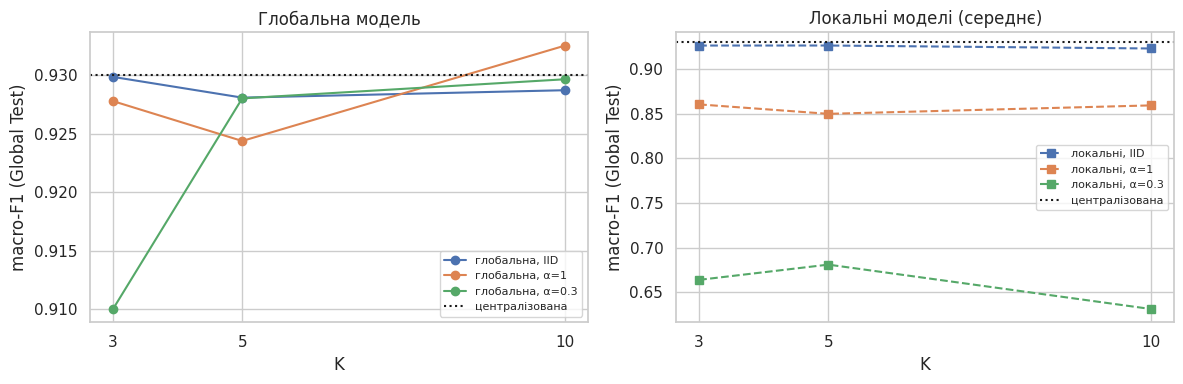

In [34]:
expA = []
for Kc in [3, 5, 10]:
    for scen, maker in [('IID', lambda K_: partition_iid(y_pool, K_)),
                        ('α=1', lambda K_: partition_dirichlet(y_pool, K_, 1, seed=SEED)),
                        ('α=0.3', lambda K_: partition_dirichlet(y_pool, K_, 0.3, seed=SEED))]:
        parts = maker(Kc)
        g, _ = run_scenario(parts, E=E_BASE)
        loc = [evaluate(m, X_test, y_test)['macro_f1'] for m in train_local_models(parts)]
        expA.append({'K': Kc, 'сценарій': scen, 'min n_k': min(map(len, parts)),
                     **{f'глоб. {k}': v for k, v in evaluate(g, X_test, y_test).items()},
                     'лок. macro-F1 (сер.)': np.mean(loc)})
expA = pd.DataFrame(expA)
display(expA)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for scen in ['IID', 'α=1', 'α=0.3']:
    s = expA[expA['сценарій'] == scen]
    ax[0].plot(s['K'], s['глоб. macro_f1'], 'o-', label=f'глобальна, {scen}')
    ax[1].plot(s['K'], s['лок. macro-F1 (сер.)'], 's--', label=f'локальні, {scen}')
for a_, t in zip(ax, ['Глобальна модель', 'Локальні моделі (середнє)']):
    a_.axhline(res_central['macro_f1'], ls=':', c='k', label='централізована')
    a_.set_xticks([3, 5, 10]); a_.set_xlabel('K'); a_.set_ylabel('macro-F1 (Global Test)'); a_.set_title(t); a_.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Що показано:** якість глобальної моделі та середньої локальної залежно від K.

**Закономірності:**
- **Глобальна модель** слабо залежить від K і при IID, і при α = 1 (macro-F1 0.924–0.933 — усі в межах ±0.5 п.п. від централізованої). При α = 0.3 і K = 3 якість найнижча (0.910): з трьома клієнтами розбиття Діріхле дало дуже нерівні частки (найменший клієнт — 406 прикладів) і сильніше перекошені набори; при K = 10 неоднорідність кожного клієнта «розбавляється» тим, що усереднюється більше різних моделей.
- **Локальні моделі** гіршають зі зростанням K (при IID 0.927 → 0.923, при α = 0.3 0.664 → 0.631): у кожного клієнта менше даних і (при Non-IID) ще менше класів.

**Чому:** загальний обсяг даних для FL не змінюється, змінюється лише те, як вони порізані. Для опуклої моделі з достатньою кількістю даних FedAvg нечутливий до K; суттєвіший вплив має *ступінь* перекосу конкретного розбиття, ніж сама кількість клієнтів. Натомість для локального навчання більше K = менше даних на кожного, тому зі зростанням K виграш від участі у федерації тільки збільшується.

### Експеримент Б. Персоналізація

Кожен клієнт ділить свій $D_k$ на локальний train (80%) і локальний test (20%). FedAvg навчається лише на локальних train-частинах; потім кожен клієнт донавчає отриману глобальну модель 1 або 2 епохи на своєму train. Порівнюємо на **локальних** тестах: глобальну, персоналізовану (1 і 2 епохи) та чисто локальну модель.

In [35]:
def local_train_test_split(parts, test_frac=0.2, seed=SEED):
    rng = np.random.default_rng(seed)
    tr, te = [], []
    for p in parts:
        p = rng.permutation(p); n_te = max(1, int(round(test_frac * len(p))))
        te.append(p[:n_te]); tr.append(p[n_te:])
    return tr, te

pers_rows = []
for scen in ['IID', 'α=0.3']:
    tr_parts, te_parts = local_train_test_split(SCENARIOS[scen])
    g_model, _ = run_scenario(tr_parts, E=E_BASE)        # FL лише на локальних train-частинах
    for k, (tr, te) in enumerate(zip(tr_parts, te_parts)):
        Xtr, Ytr, Xte, yte = X_pool[tr], one_hot(y_pool[tr], C), X_pool[te], y_pool[te]
        row = {'сценарій': scen, 'client': k, 'n_train': len(tr), 'n_test': len(te),
               'глобальна': accuracy_score(yte, g_model.predict(Xte))}
        for ep in [1, 2]:
            pm = SoftmaxRegression(d, C, lam=LAM); pm.set_params(g_model.get_params())
            pm.fit(Xtr, Ytr, epochs=ep, lr=LR, batch_size=BS, seed=SEED + k)
            row[f'персоналіз. {ep} еп.'] = accuracy_score(yte, pm.predict(Xte))
        lm = SoftmaxRegression(d, C, lam=LAM); lm.fit(Xtr, Ytr, epochs=EPOCHS, lr=LR, batch_size=BS, seed=SEED + k)
        row['лише локальна'] = accuracy_score(yte, lm.predict(Xte))
        pers_rows.append(row)
pers = pd.DataFrame(pers_rows)
display(pers)
display(pers.groupby('сценарій')[['глобальна', 'персоналіз. 1 еп.', 'персоналіз. 2 еп.', 'лише локальна']].mean()
        .style.format('{:.4f}').set_caption('Середня accuracy на локальних тестових вибірках'))

,сценарій,client,n_train,n_test,глобальна,персоналіз. 1 еп.,персоналіз. 2 еп.,лише локальна
0,IID,0,1517,379,0.9314,0.9367,0.9314,0.9367
1,IID,1,1517,379,0.9340,0.9393,0.9340,0.9340
2,IID,2,1517,379,0.9182,0.9156,0.9156,0.9156
3,IID,3,1517,379,0.9472,0.9472,0.9393,0.9420
4,IID,4,1516,379,0.9340,0.9393,0.9367,0.9367
5,α=0.3,0,1204,301,0.9668,0.9801,0.9867,0.9834
6,α=0.3,1,1229,307,0.9479,0.9642,0.9674,0.9674
7,α=0.3,2,1053,263,0.8821,0.9202,0.9240,0.9163
8,α=0.3,3,837,209,0.9043,0.9856,0.9856,0.9952
9,α=0.3,4,3261,815,0.9399,0.9460,0.9448,0.9472


,глобальна,персоналіз. 1 еп.,персоналіз. 2 еп.,лише локальна
сценарій,,,,
IID,0.9330,0.9356,0.9314,0.9330
α=0.3,0.9282,0.9592,0.9617,0.9619


**Що показано:** accuracy кожного типу моделі на локальному тесті кожного клієнта та середнє по клієнтах.

**Закономірності:**
- **IID:** усі чотири варіанти майже однакові (≈ 0.93) — локальний розподіл збігається з глобальним, тож персоналізувати нічого.
- **α = 0.3:** персоналізація дає великий приріст: середня accuracy 0.928 (глобальна) → 0.959 (1 епоха) → 0.962 (2 епохи); найсильніше — у клієнта 3 (0.904 → 0.986), в якого 80% даних — SIRA. Чисто локальні моделі на своєму розподілі теж сильні (0.962), але, як ми бачили в Експерименті 1, вони провально працюють на глобальному розподілі.

**Чому:** глобальна модель — компроміс між усіма клієнтами; 1–2 епохи донавчання зсувають bias і ваги у бік локальних пропорцій класів, зберігаючи знання про інші класи. Персоналізація особливо корисна саме в Non-IID сценаріях і майже нічого не коштує: одна-дві локальні епохи, без додаткового обміну з сервером.

---
## Відповіді на теоретичні питання

**1. Чому для багатокласової класифікації використовують softmax?**
Softmax перетворює вектор довільних дійсних оцінок $z\in\mathbb R^C$ на коректний розподіл імовірностей: усі $P_c>0$ і $\sum_c P_c=1$. Він монотонний (більший логіт — більша ймовірність), диференційований і є природним узагальненням сигмоїди (при $C=2$ softmax зводиться до $\sigma(z_1-z_2)$). Статистично — це модель, у якій логарифм відношення шансів двох класів лінійний за ознаками. Разом із крос-ентропією дає дуже простий градієнт $P-Y$.

**2. Чому крос-ентропія — природна функція втрат для логістичної регресії?**
Модель задає категоріальний розподіл $p(y\mid x)$; мінімізація крос-ентропії рівносильна **максимізації правдоподібності** даних ($-\log$ правдоподібності = крос-ентропія). Крім того: (а) для softmax-моделі вона **опукла** за $W,b$ — немає локальних мінімумів; (б) градієнт $X^\top(P-Y)/m$ не «насичується», на відміну від MSE з softmax, де при впевнено хибному прогнозі градієнт майже нульовий; (в) сильно штрафує впевнені помилки ($-\log P\to\infty$ при $P\to0$), що стимулює калібровані ймовірності.

**3. Чим відрізняється Ridge-регуляризація від Lasso?**
Ridge (L2) додає $\frac\lambda2\|W\|_2^2$, Lasso (L1) — $\lambda\|W\|_1$. L2 рівномірно зменшує всі ваги пропорційно їхній величині, але майже ніколи не робить їх рівно нулем; гладка, диференційована, добре працює з корельованими ознаками (розподіляє вагу між ними). L1 має «гострий» кут у нулі, тому обнуляє частину ваг — дає **розріджену** модель і фактично відбирає ознаки; серед групи корельованих ознак зазвичай лишає одну. L1 недиференційована в нулі, тож потребує субградієнтів або проксимальних методів. З байєсівського погляду L2 — гаусівський апріорний розподіл ваг, L1 — лапласівський.

**4. Чому зміщення $b$ зазвичай не регуляризують?**
Регуляризація обмежує *складність* моделі — наскільки сильно вихід залежить від ознак. Зміщення не множиться на ознаки, воно лише зсуває логіти й відповідає за базові частоти класів (апріорні ймовірності). Штрафування $b$ тягнуло б прогнози до рівномірного розподілу класів навіть без жодної користі проти перенавчання, а результат залежав би від центрування даних. Параметрів $b$ лише $C$, тож перенавчитися через них неможливо.

**5. Що таке Data Leakage?**
Використання під час навчання чи вибору моделі інформації, яка недоступна в реальному застосуванні — зазвичай даних з валідаційної/тестової вибірки або ознак, що «підглядають» у ціль (наприклад, обчислені після події). Типові джерела: масштабування/кодування/відбір ознак до розбиття, дублікати в train і test, target encoding без розбиття, підбір гіперпараметрів на тесті. Наслідок — завищена оцінка якості, яка не підтверджується на нових даних.

**6. Чому тестову вибірку не можна використовувати для підбору гіперпараметрів?**
Бо тоді тест стає частиною процесу навчання: обираючи конфігурацію з найкращим тестовим результатом, ми підганяємо модель під конкретний тестовий набір (включно з його випадковим шумом). Отримана оцінка стає оптимістично зміщеною і вже не відображає якість на нових даних. Для вибору є валідація (або крос-валідація), а тест — одноразова фінальна перевірка.

**7. Чому параметри масштабування треба навчати лише на тренувальних даних?**
Середні та дисперсії — це параметри, оцінені з даних. Якщо рахувати їх з урахуванням val/test, інформація про розподіл тестових ознак «просочується» в модель (Data Leakage). У реальності нові об'єкти приходять по одному, і для них доступні лише статистики, отримані на train — тож оцінювати модель треба в тих самих умовах. У FL додатково: тест/валідація належать серверу, і клієнти їх не бачать.

**8. Що таке федеративне навчання і які його основні переваги?**
Це спосіб спільного навчання моделі кількома учасниками без передачі сирих даних: клієнти навчають модель локально, а на сервер надсилають лише параметри (або оновлення), які сервер агрегує в глобальну модель. Переваги: **приватність і відповідність регуляціям** (дані не залишають пристрій/організацію — медицина, банки, телефони); доступ до значно більшого й різноманітнішого обсягу даних, ніж у будь-якого учасника окремо; менший мережевий трафік (передаються параметри, а не датасети); розподіл обчислень між клієнтами; модель, кращу за будь-яку локальну (що видно в нашій таблиці порівняння).

**9. Чому сервер не повинен отримувати сирі дані клієнтів?**
Бо головна мета FL — приватність: сирі дані можуть містити персональну чи комерційно чутливу інформацію, передача її на сервер створює єдину точку витоку й порушує закони (GDPR, медична таємниця). Якщо сервер отримає сирі дані, FL втрачає сенс — це вже звичайне централізоване навчання. (Варто пам'ятати, що навіть параметри можуть частково розкривати дані, тому на практиці додають secure aggregation і диференційну приватність.)

**10. Чому FedAvg зважує за кількістю прикладів?**
Бо глобальна ціль — середня втрата по всіх прикладах: $J=\sum_k\frac{n_k}{n}J_k$. Зважування $n_k/n$ робить агрегацію узгодженою з цією ціллю: кожен *приклад* має однаковий вплив незалежно від того, у якого клієнта він лежить. Крім того, модель клієнта з великим $n_k$ оцінена надійніше (менша дисперсія), тож їй доцільно довіряти більше.

**11. Що станеться при агрегації без зважування?**
Сервер оптимізуватиме іншу ціль $\frac1K\sum_k J_k$, де приклади малих клієнтів мають непропорційно великий вплив. Глобальна модель зміститься в бік розподілів малих клієнтів, стане шумнішою і вразливішою до поганих/зловмисних учасників (клієнт із 7 прикладами = клієнт із 3500). При однакових $n_k$ (IID у нас) різниці немає. У нашому експерименті при α = 0.1 просте середнє випадково покращило macro-F1, бо малі клієнти тримали рідкісні класи — але це ефект конкретного розбиття, а не принципова перевага.

**12. Що таке Non-IID дані?**
Дані клієнтів, які не є незалежними однаково розподіленими вибірками з одного розподілу: у різних клієнтів різні розподіли. Види: перекіс міток (label skew — різні пропорції класів, як у нас через Діріхле), перекіс ознак (covariate shift — різні пристрої/умови зйомки), різний обсяг даних, різна $p(y\mid x)$ (різна розмітка), часові відмінності.

**13. Чому FL погіршується на Non-IID даних?**
Локальні оптимуми клієнтів не збігаються з глобальним, тож їхні оновлення систематично спрямовані в різні боки. Середнє кількох локально оптимізованих моделей не дорівнює моделі, оптимальній для об'єднаних даних (для нелінійних моделей — навіть не обов'язково хороша модель), тому FedAvg збігається повільніше, коливається і може застрягнути в зміщеній точці. Окрім того, клієнти без певних класів дають «негативний» сигнал для цих класів. У нас: при α = 0.1 глобальний macro-F1 впав з 0.928 (IID) до 0.893.

**14. Що таке client drift?**
Відхилення локальних моделей від глобальної (і від глобального оптимуму) в бік власних локальних оптимумів під час кількох кроків локального навчання між синхронізаціями. При Non-IID дрейф систематичний і не компенсується усередненням, що зміщує глобальну модель. Ми вимірювали його як середнє $\|W_k-W_{\text{global}}\|_F$: він росте з E і в 2–3 рази більший при Non-IID.

**15. Як кількість локальних епох впливає на глобальну модель?**
Більше E — менше раундів комунікації для тієї самої кількості обчислень і швидший прогрес на початку, але сильніший client drift. При IID це майже безкоштовно (у нас E = 1/5/10 дали однакову якість). При сильно Non-IID великий E зміщує точку збіжності: при α = 0.1 macro-F1 0.917 (E = 1) → 0.893 (E = 5) → 0.885 (E = 10). Тобто E — компроміс між комунікаційною ефективністю та точністю; при неоднорідних даних його слід зменшувати або використовувати FedProx/SCAFFOLD.

**16. Чи може глобальна модель бути гіршою за централізовану? Чому?**
Так, і зазвичай буває (у кращому разі — рівна). Централізована модель мінімізує втрату напряму по всіх даних; FedAvg лише наближає цей оптимум через усереднення моделей, що навчались на частинах даних. Похибку додають неоднорідність клієнтів (client drift), обмежена кількість раундів, часткова участь клієнтів, шум SGD. При IID і достатній кількості раундів різниця мізерна (у нас 0.928 проти 0.930 macro-F1), при α = 0.1 — суттєва (0.893).

**17. Які метрики краще використовувати для багатокласової класифікації з дисбалансом?**
**Macro-F1** (F1 рахується для кожного класу і просто усереднюється — рідкісний клас важить стільки ж, скільки частий), **balanced accuracy** (середній recall по класах), **confusion matrix** і per-class precision/recall/F1 — щоб бачити, *які* класи плутаються. **Log-loss** — для оцінки якості ймовірностей. Звичайна accuracy при дисбалансі може бути високою навіть у моделі, що ігнорує рідкісні класи, тому окремо її недостатньо. Weighted-F1 теж зважує за частотою класів, тож маскує проблеми рідкісних класів.

---
## Загальний висновок

1. **Дані та підготовка.** Dry Bean — 13.5 тис. зернин, 7 незбалансованих сортів (6.8 : 1), 16 числових геометричних ознак без пропусків; 68 дублікатів видалено. Розбиття 70/15/15 (FL Train Pool / Validation / Test) виконано стратифіковано **до** будь-яких перетворень. Відбір ознак за F-статистикою з відсіюванням майже-дублікатів ($|r|>0.95$) на FL Train Pool скоротив 16 ознак до 10 без втрати якості. Стандартизацію реалізовано федеративно (агрегація локальних середніх і дисперсій) — вона точно збігається з централізованою для будь-якого розбиття.

2. **Модель.** Softmax-регресію з L2 реалізовано на numpy повністю векторизовано; градієнти підтверджено чисельною перевіркою (похибка ~$10^{-10}$), результат збігається з `sklearn` (допоміжна перевірка).

3. **Централізована модель** (lr = 0.5, batch = 32, λ = 0, 60 епох): Global Test accuracy 0.918, macro-F1 0.930, balanced accuracy 0.931, log-loss 0.229. Перенавчання немає, тому Ridge не покращує результат. Основні помилки — SIRA ↔ DERMASON і BARBUNYA ↔ CALI.

4. **Федеративне навчання.** FedAvg при IID і помірній неоднорідності (α ≥ 0.3) практично досягає централізованої якості (macro-F1 0.924–0.928), при цьому в рази перевершує локальні моделі (при α = 0.3 середній локальний macro-F1 лише 0.68). Сильна неоднорідність (α = 0.1) помітно погіршує глобальну модель (0.893).

5. **Локальні епохи і client drift.** Дрейф росте з E і при Non-IID в 2–3 рази більший. При IID E не впливає на якість, при α = 0.1 великий E погіршує глобальну модель (0.917 → 0.885 для E = 1 → 10).

6. **Агрегація.** Зважування за $n_k$ узгоджене з глобальною ціллю; при рівних $n_k$ воно тотожне простому середньому; при нерівних — просте середнє дає малим клієнтам непропорційний вплив.

7. **Додатково.** Кількість клієнтів (3/5/10) на глобальну модель впливає слабо, а на локальні — негативно. Персоналізація (1–2 епохи донавчання глобальної моделі) при α = 0.3 підвищує accuracy на локальних тестах з 0.928 до 0.962 практично без додаткових витрат.

**Практичний підсумок:** для задач, де дані не можна зводити в одне місце, FL з простою опуклою моделлю дає майже централізовану якість; головний ризик — неоднорідність даних клієнтів, з якою варто боротися меншою кількістю локальних епох, методами проти дрейфу та персоналізацією.